## CREDIT RISK PREDICTION & LOAN DEFAULT ANALYSIS
### PROJECT OVERVIEW

This project explores historical loan application data to understand the factors associated with loan repayment difficulties and develop a machine learning approach for predicting loan default.

### BUSINESS PROBLEM

Lenders need to assess the credit risk of applicants before approving loans. However, accurately identifying applicants who may default can be challenging, particularly when working with a large and diverse set of financial, demographic, and credit-related information.

The objective of this project is to use historical application data to analyse default patterns and build a model that can help identify applicants with higher risk of default.

### INITIAL STAGE

In [5]:
# import the necessary libraries and modules

# data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier , plot_importance

# model selection and preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler , LabelEncoder ,OneHotEncoder

# metrics for evaluation and validation
from sklearn.metrics import average_precision_score, recall_score, precision_score, accuracy_score, f1_score, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# imbalance and interpretability
from imblearn.over_sampling import SMOTE
import shap

# utilities
import warnings
warnings.filterwarnings("ignore")

from imblearn.pipeline import Pipeline
from google.colab import files


### DATASET COLLECTION AND EXPLORATION

In [6]:
# load the dataset

df = pd.read_csv('application_train.csv')

In [7]:
# check the dataset

df.head(10)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
5,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0
6,100009,0,Cash loans,F,Y,Y,1,171000.0,1560726.0,41301.0,...,0,0,0,0,0.0,0.0,0.0,1.0,1.0,2.0
7,100010,0,Cash loans,M,Y,Y,0,360000.0,1530000.0,42075.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
8,100011,0,Cash loans,F,N,Y,0,112500.0,1019610.0,33826.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
9,100012,0,Revolving loans,M,N,Y,0,135000.0,405000.0,20250.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# check the shape

df.shape

(307511, 122)

In [9]:
# check for datatypes

df.dtypes

,0
SK_ID_CURR,int64
TARGET,int64
NAME_CONTRACT_TYPE,object
CODE_GENDER,object
FLAG_OWN_CAR,object
...,...
AMT_REQ_CREDIT_BUREAU_DAY,float64
AMT_REQ_CREDIT_BUREAU_WEEK,float64
AMT_REQ_CREDIT_BUREAU_MON,float64
AMT_REQ_CREDIT_BUREAU_QRT,float64


In [10]:
# gather basic info about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [11]:
# gather basic statistics about the dataset

df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [12]:
# check the target column distribution

df['TARGET'].value_counts()

,count
TARGET,
0,282686
1,24825


### DATA PREPROCESSING

##### 1. DATA CLEANING AND TRANSFORMATION

In [13]:
# display missing value count and percentage for all columns

missing_values_count = df.isnull().sum()
missing_values_percentage = df.isnull().sum()/len(df) * 100

df_missing = pd.DataFrame({'column_name': df.columns,'missing_count': missing_values_count,
                                 'percent_missing': missing_values_percentage})

In [14]:
df.shape

(307511, 122)

In [15]:
df_missing.sort_values(ascending=False, by='missing_count')

,column_name,missing_count,percent_missing
COMMONAREA_AVG,COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,NONLIVINGAPARTMENTS_MODE,213514,69.432963
...,...,...,...
FLAG_DOCUMENT_16,FLAG_DOCUMENT_16,0,0.000000
FLAG_DOCUMENT_15,FLAG_DOCUMENT_15,0,0.000000
FLAG_DOCUMENT_14,FLAG_DOCUMENT_14,0,0.000000
FLAG_DOCUMENT_20,FLAG_DOCUMENT_20,0,0.000000


In [16]:
# checking duplicates

df.duplicated().sum()

np.int64(0)

In [17]:
# drop identifier column

df.drop(columns=['SK_ID_CURR'], inplace=True)

#### ANOMALY HANDLING

In [18]:
df.columns = df.columns.str.lower()

In [19]:
# convert negative days columns to positive years

df['days_birth'] = abs(df['days_birth']) / 365
df['days_employed'] = abs(df['days_employed']) / 365
df['days_registration'] = abs(df['days_registration']) / 365
df['days_id_publish'] = abs(df['days_id_publish']) / 365
df['days_last_phone_change'] = abs(df['days_last_phone_change']) / 365

In [20]:
# rename converted columns to reflect actual meaning

df.rename(columns={
    'days_birth': 'age_years',
    'days_employed': 'employment_years',
    'days_registration': 'registration_years',
    'days_id_publish': 'id_publish_years'
}, inplace=True)
df.head(10)

,target,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,amt_goods_price,...,flag_document_18,flag_document_19,flag_document_20,flag_document_21,amt_req_credit_bureau_hour,amt_req_credit_bureau_day,amt_req_credit_bureau_week,amt_req_credit_bureau_mon,amt_req_credit_bureau_qrt,amt_req_credit_bureau_year
0,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
5,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,454500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0
6,0,Cash loans,F,Y,Y,1,171000.0,1560726.0,41301.0,1395000.0,...,0,0,0,0,0.0,0.0,0.0,1.0,1.0,2.0
7,0,Cash loans,M,Y,Y,0,360000.0,1530000.0,42075.0,1530000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
8,0,Cash loans,F,N,Y,0,112500.0,1019610.0,33826.5,913500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
9,0,Revolving loans,M,N,Y,0,135000.0,405000.0,20250.0,405000.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


### EXPLORATORY DATA ANALYSIS

In [21]:
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

#### NUMERICAL EDA

Firstly we have to find those features whose datatype is int but has binary values (0 or 1)..so these will be inlcuded in Categorical features

In [22]:
binary_cols = [
    col for col in df.select_dtypes(include='number').columns
    if set(df[col].dropna().unique()).issubset({0, 1})
]

print(binary_cols)

['target', 'flag_mobil', 'flag_emp_phone', 'flag_work_phone', 'flag_cont_mobile', 'flag_phone', 'flag_email', 'reg_region_not_live_region', 'reg_region_not_work_region', 'live_region_not_work_region', 'reg_city_not_live_city', 'reg_city_not_work_city', 'live_city_not_work_city', 'flag_document_2', 'flag_document_3', 'flag_document_4', 'flag_document_5', 'flag_document_6', 'flag_document_7', 'flag_document_8', 'flag_document_9', 'flag_document_10', 'flag_document_11', 'flag_document_12', 'flag_document_13', 'flag_document_14', 'flag_document_15', 'flag_document_16', 'flag_document_17', 'flag_document_18', 'flag_document_19', 'flag_document_20', 'flag_document_21']


In [23]:
len(binary_cols)

33

In [24]:
numerical_cols = [
    col for col in df.columns
    if col not in binary_cols + ['TARGET']
    and df[col].dtype in ['int64', 'float64']
]

categorical_cols = [
    col for col in df.columns
    if col not in binary_cols + ['TARGET']
    and df[col].dtype == 'object'
]

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['cnt_children', 'amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price', 'region_population_relative', 'age_years', 'employment_years', 'registration_years', 'id_publish_years', 'own_car_age', 'cnt_fam_members', 'region_rating_client', 'region_rating_client_w_city', 'hour_appr_process_start', 'ext_source_1', 'ext_source_2', 'ext_source_3', 'apartments_avg', 'basementarea_avg', 'years_beginexpluatation_avg', 'years_build_avg', 'commonarea_avg', 'elevators_avg', 'entrances_avg', 'floorsmax_avg', 'floorsmin_avg', 'landarea_avg', 'livingapartments_avg', 'livingarea_avg', 'nonlivingapartments_avg', 'nonlivingarea_avg', 'apartments_mode', 'basementarea_mode', 'years_beginexpluatation_mode', 'years_build_mode', 'commonarea_mode', 'elevators_mode', 'entrances_mode', 'floorsmax_mode', 'floorsmin_mode', 'landarea_mode', 'livingapartments_mode', 'livingarea_mode', 'nonlivingapartments_mode', 'nonlivingarea_mode', 'apartments_medi', 'basementarea_medi', 'years_begine

In [25]:
categorical_cols

['name_contract_type',
 'code_gender',
 'flag_own_car',
 'flag_own_realty',
 'name_type_suite',
 'name_income_type',
 'name_education_type',
 'name_family_status',
 'name_housing_type',
 'occupation_type',
 'weekday_appr_process_start',
 'organization_type',
 'fondkapremont_mode',
 'housetype_mode',
 'wallsmaterial_mode',
 'emergencystate_mode']

  ###### So we have to filter columns from numerical columns for EDA

  ###### 1. So firstly we will check the correlation of columns with target for those who have more missing values

In [26]:
df_most_missing = df_missing[df_missing['percent_missing']>50]
df_most_missing['target'] = df['target']

In [27]:
list_most_missing = df_most_missing['column_name'].tolist()

In [28]:
# list containing most missing columns
list_most_missing

['OWN_CAR_AGE',
 'EXT_SOURCE_1',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BUILD_AVG',
 'COMMONAREA_AVG',
 'ELEVATORS_AVG',
 'ENTRANCES_AVG',
 'FLOORSMIN_AVG',
 'LANDAREA_AVG',
 'LIVINGAPARTMENTS_AVG',
 'LIVINGAREA_AVG',
 'NONLIVINGAPARTMENTS_AVG',
 'NONLIVINGAREA_AVG',
 'APARTMENTS_MODE',
 'BASEMENTAREA_MODE',
 'YEARS_BUILD_MODE',
 'COMMONAREA_MODE',
 'ELEVATORS_MODE',
 'ENTRANCES_MODE',
 'FLOORSMIN_MODE',
 'LANDAREA_MODE',
 'LIVINGAPARTMENTS_MODE',
 'LIVINGAREA_MODE',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAREA_MODE',
 'APARTMENTS_MEDI',
 'BASEMENTAREA_MEDI',
 'YEARS_BUILD_MEDI',
 'COMMONAREA_MEDI',
 'ELEVATORS_MEDI',
 'ENTRANCES_MEDI',
 'FLOORSMIN_MEDI',
 'LANDAREA_MEDI',
 'LIVINGAPARTMENTS_MEDI',
 'LIVINGAREA_MEDI',
 'NONLIVINGAPARTMENTS_MEDI',
 'NONLIVINGAREA_MEDI',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE']

###Observation:
`Since missing percentages in these columns are greater than 50 we have to check their correlation with the target.`

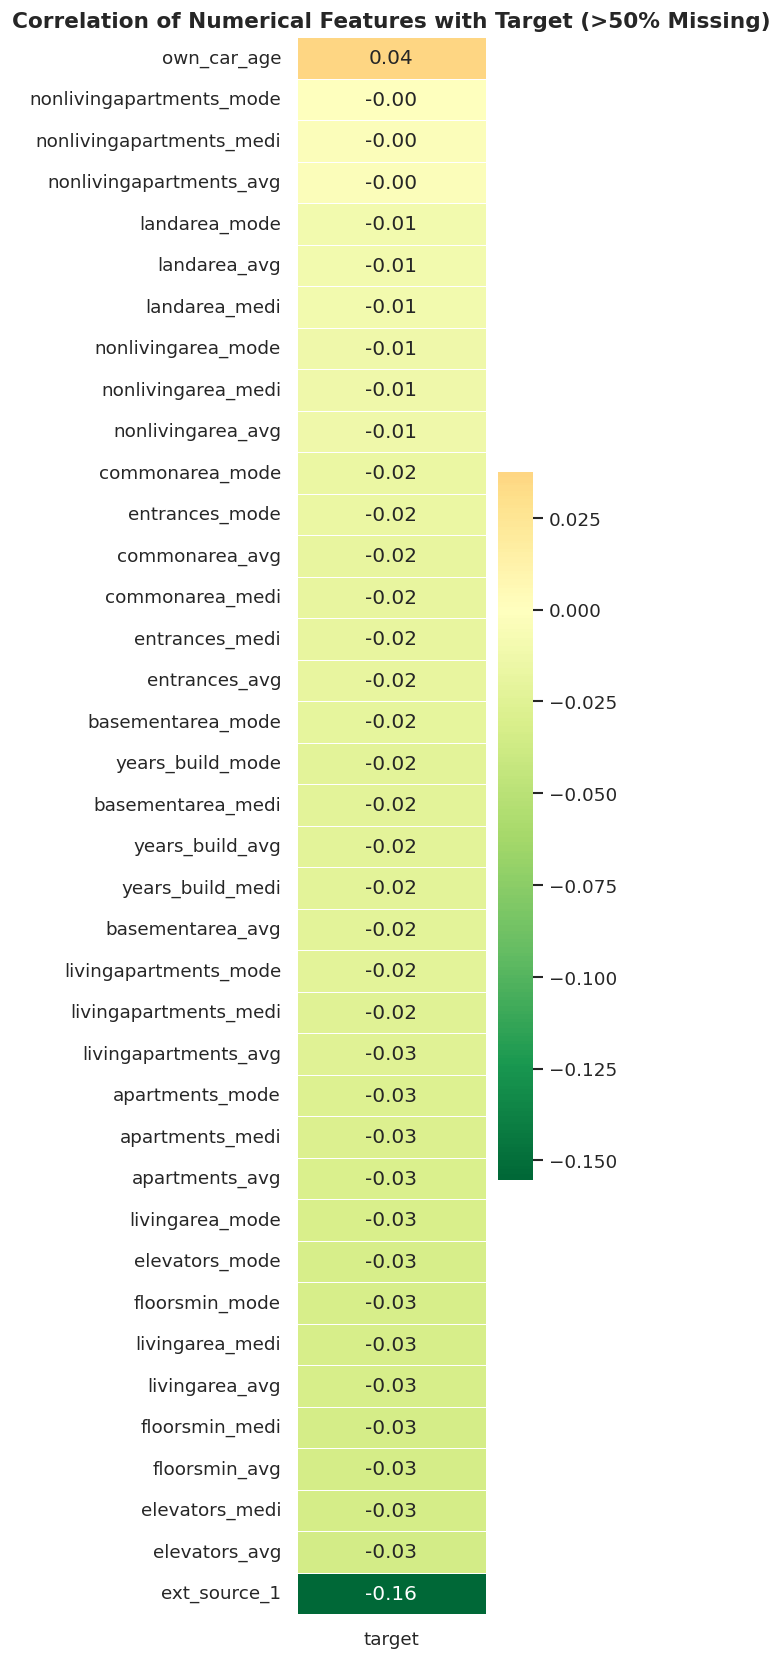

In [29]:
# correlation heatmap of numerical features with target
# only for numerical features having >50% missing values

num_cols = df.select_dtypes(include='number').columns.tolist()

# Keep only numerical columns with >50% missing values
num_cols = [
    col for col in num_cols
    if df[col].isnull().mean() * 100 > 50
]

corr_with_target = (
    df[num_cols + ['target']]
    .corr()[['target']]
    .drop('target')
    .sort_values('target', ascending=False)
)

plt.figure(figsize=(5, 14))

sns.heatmap(
    corr_with_target,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'shrink': 0.6}
)

plt.title(
    'Correlation of Numerical Features with Target (>50% Missing)',
    fontweight='bold'
)

plt.tight_layout()
plt.show()

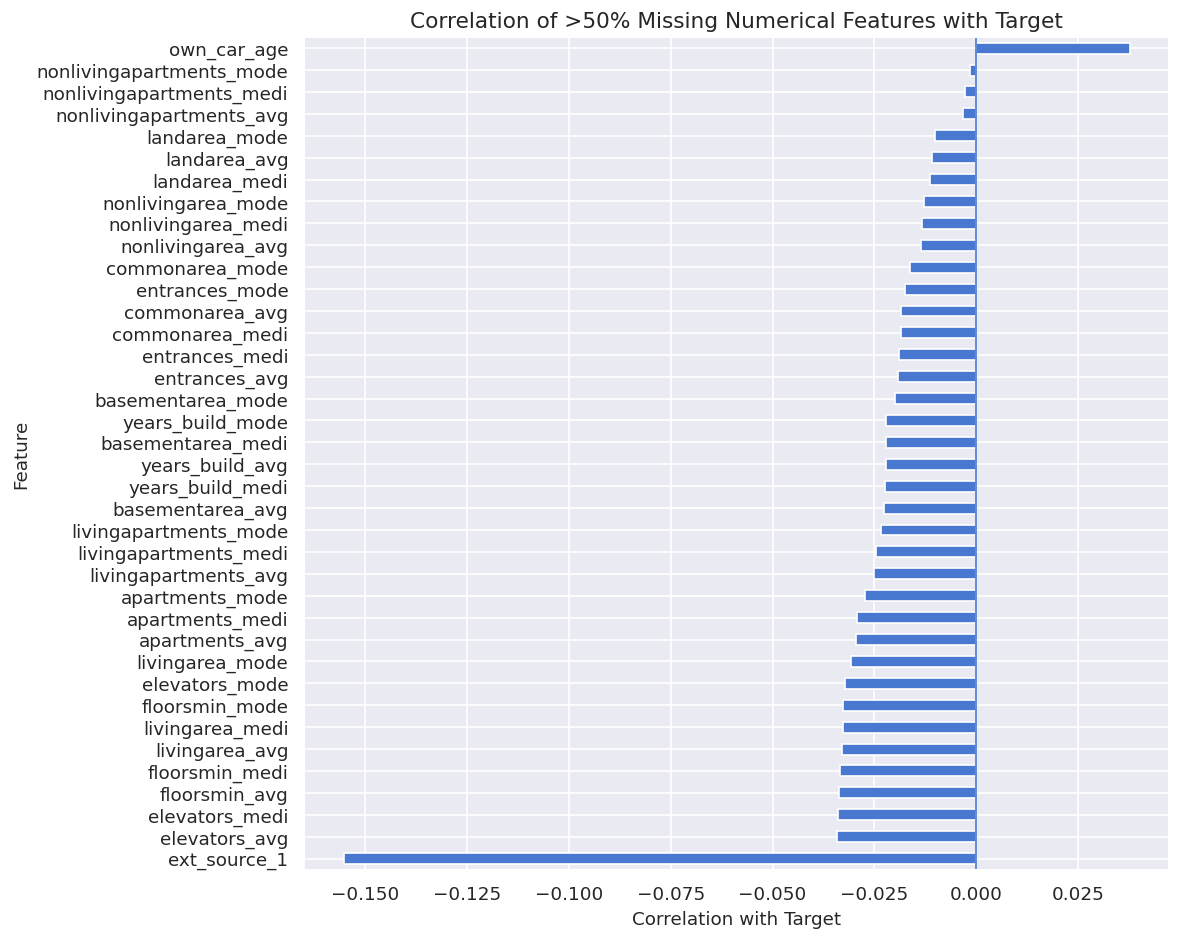

In [30]:
plt.figure(figsize=(10, 8))

corr_with_target['target'].sort_values().plot(kind='barh')

plt.axvline(0, linewidth=1)
plt.xlabel('Correlation with Target')
plt.ylabel('Feature')
plt.title('Correlation of >50% Missing Numerical Features with Target')

plt.tight_layout()
plt.show()

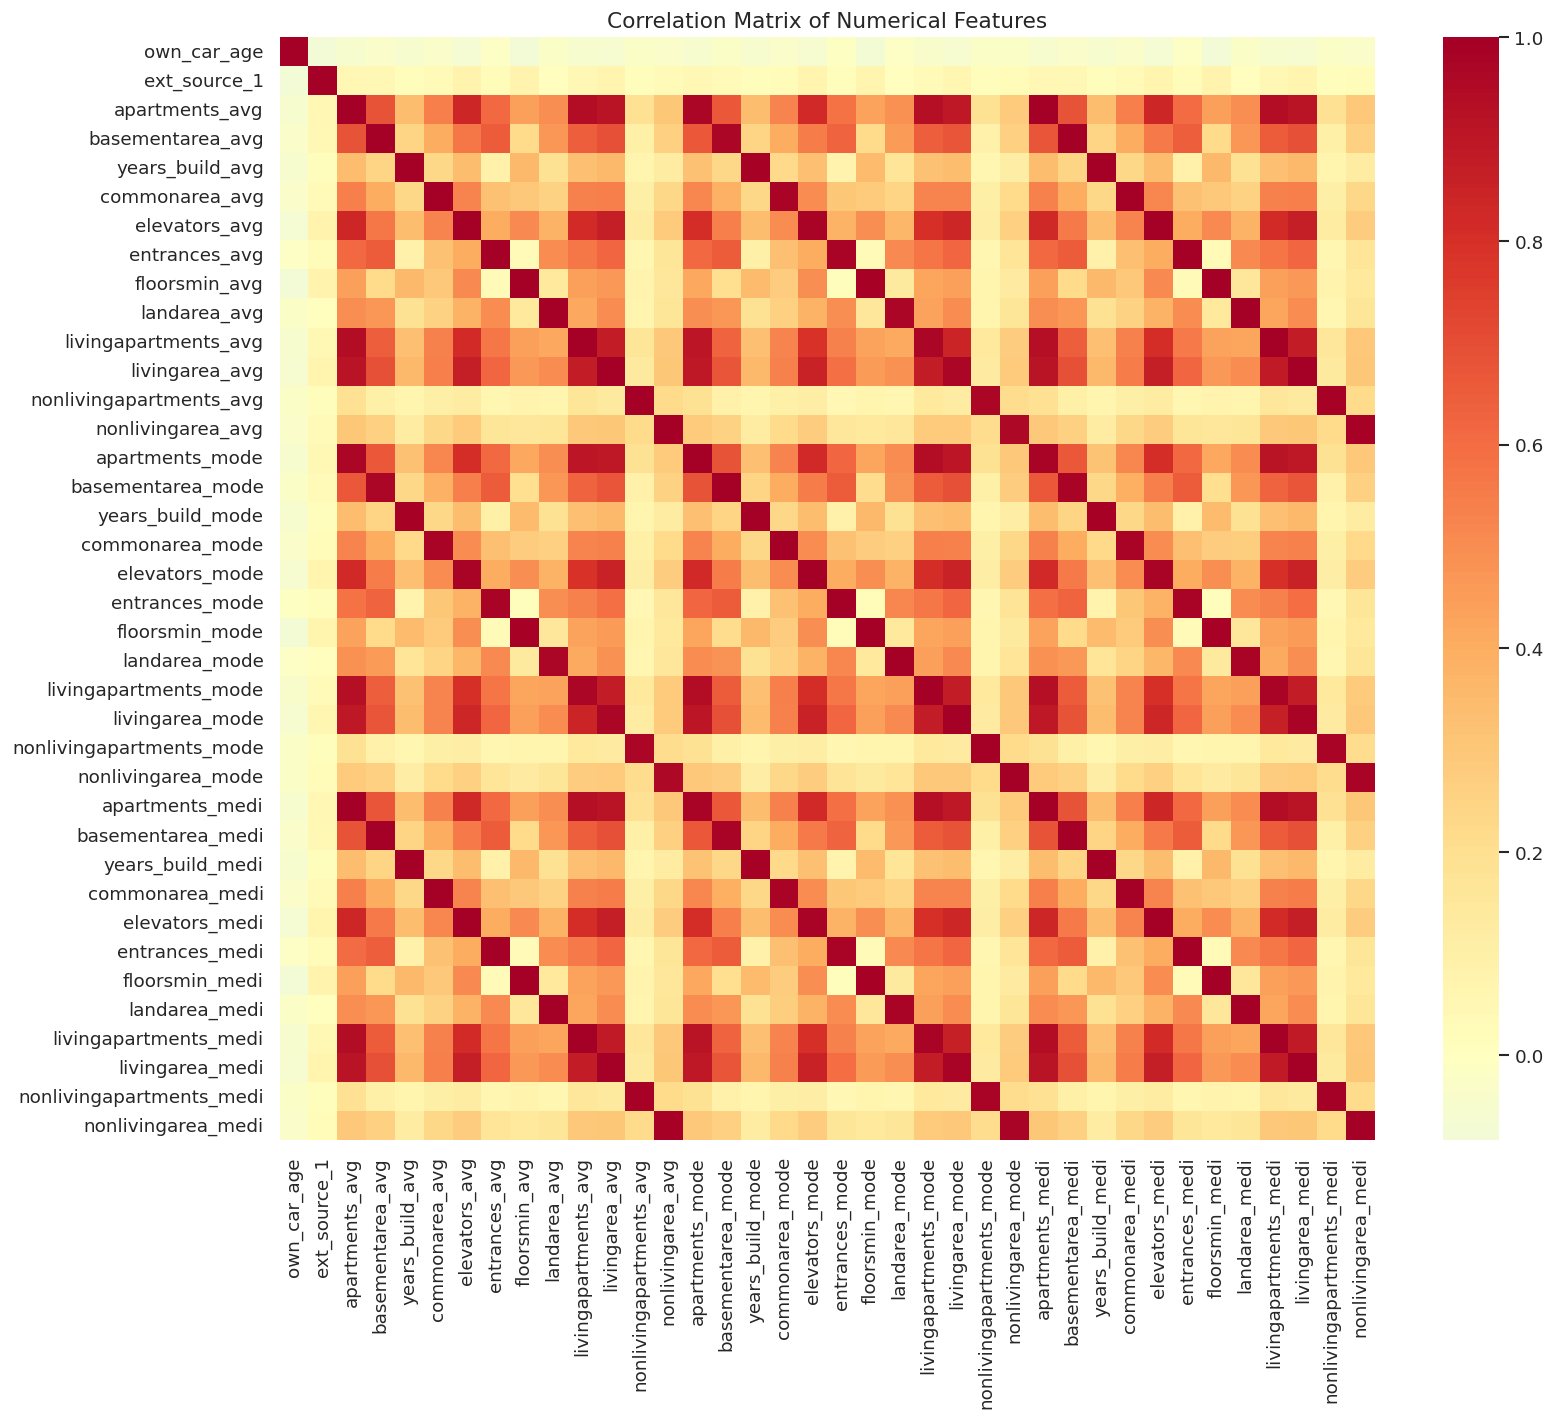

In [31]:
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='RdYlBu_r', center=0)
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

### Observation:
1. Since these features have missing values percentage > 50% and very less correlation with target so either they have to be removed or combined.

2. All the features ending with _AVG,_MOD,_MEDI are highly correlated and eventually depicting same information which can cause multicollinearity so we will create combine these features to make new ones in feature engineering.


Now let's observe the categorical features

In [32]:
# categorical columns with missing percentage > 50%
cat_missing_cols = [
    col for col in categorical_cols
    if df[col].isnull().mean() * 100 > 50
]

print(cat_missing_cols)

['fondkapremont_mode', 'housetype_mode', 'wallsmaterial_mode']


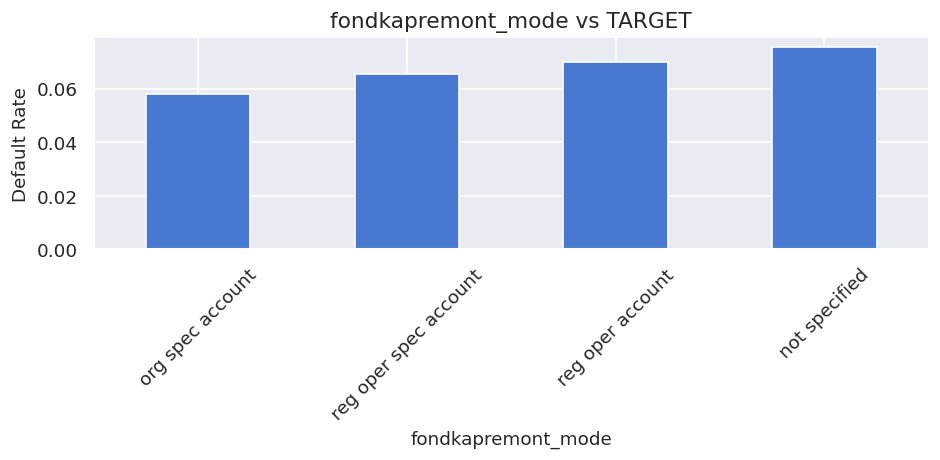

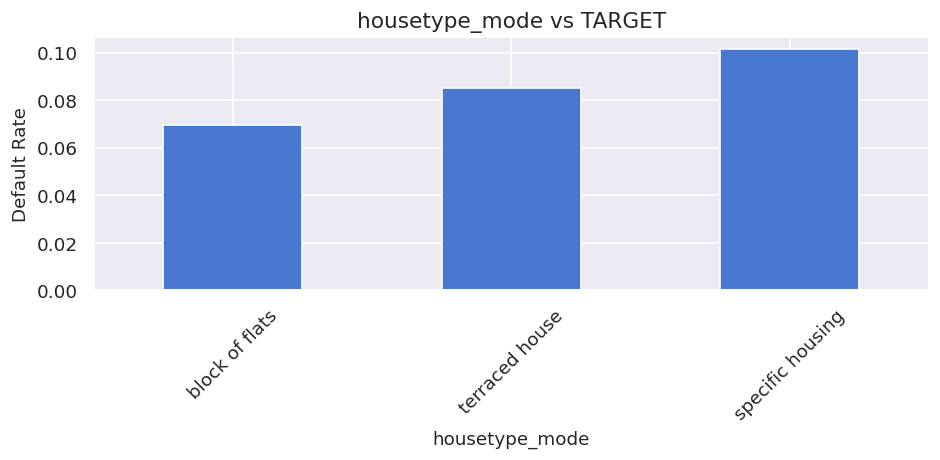

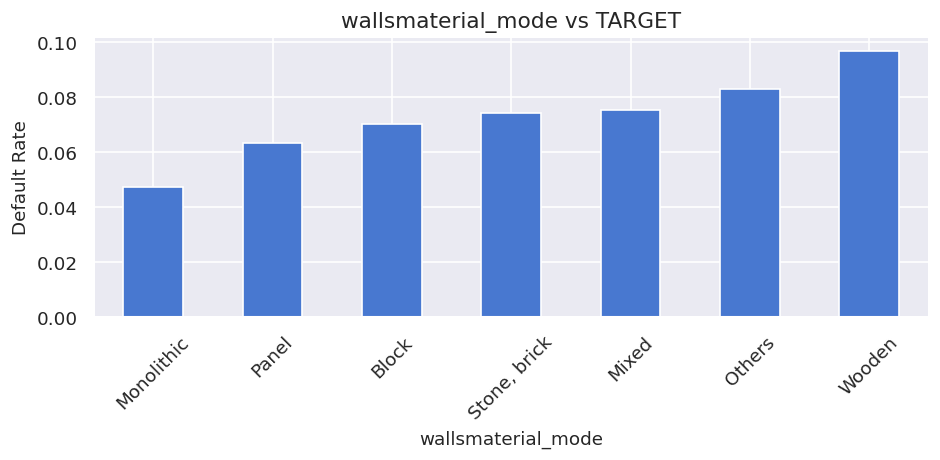

In [33]:
for col in cat_missing_cols:
    df.groupby(col)['target'].mean().sort_values().plot(
        kind='bar', figsize=(8, 4)
    )
    plt.ylabel('Default Rate')
    plt.title(f'{col} vs TARGET')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

####Observation:

Categories in the fondkapremont_mode feature have comparable default rate so we can conclude that this feature is not contributing much to the target.
We can either remove or combine it

In [34]:
#removing that feature
df.drop(columns=['fondkapremont_mode'], inplace=True)

In [35]:
df[binary_cols].isnull().sum()

,0
target,0
flag_mobil,0
flag_emp_phone,0
flag_work_phone,0
flag_cont_mobile,0
flag_phone,0
flag_email,0
reg_region_not_live_region,0
reg_region_not_work_region,0
live_region_not_work_region,0


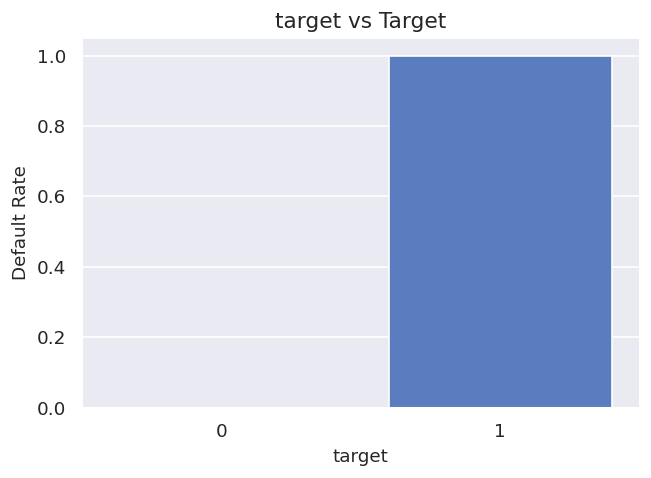

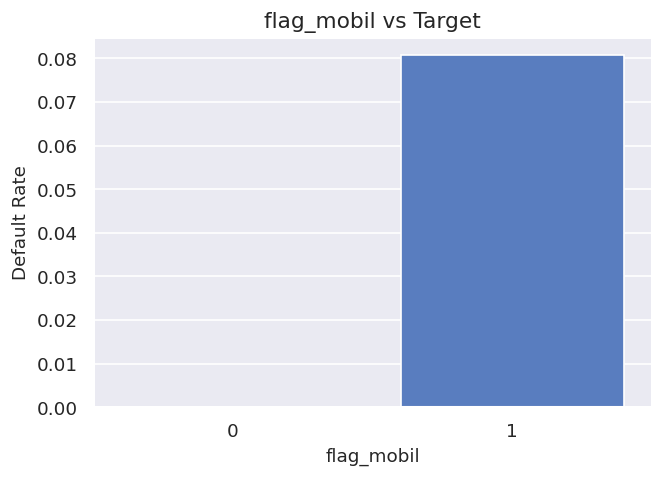

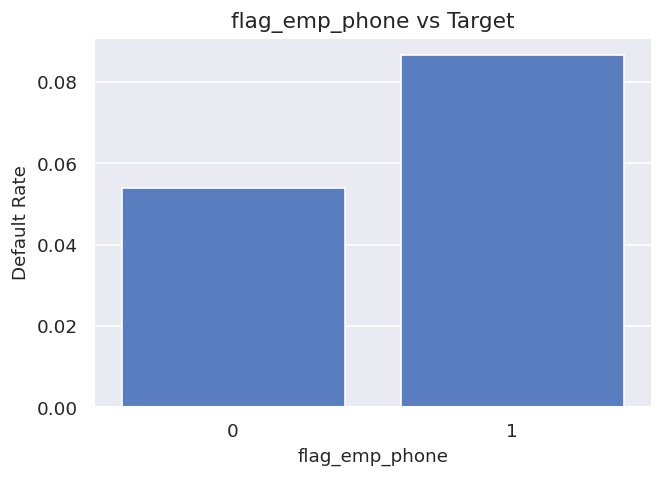

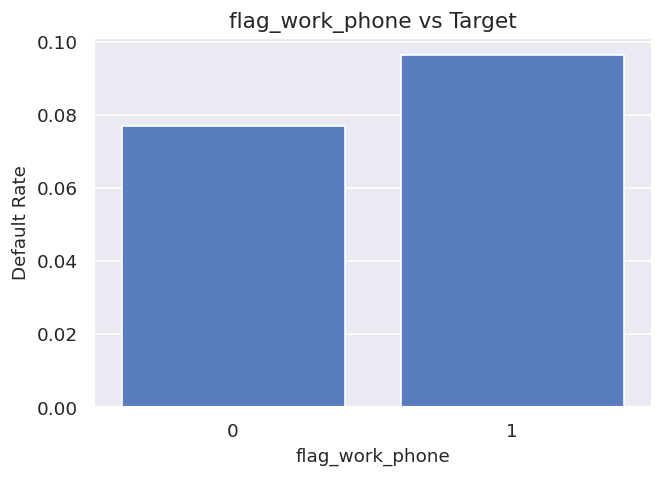

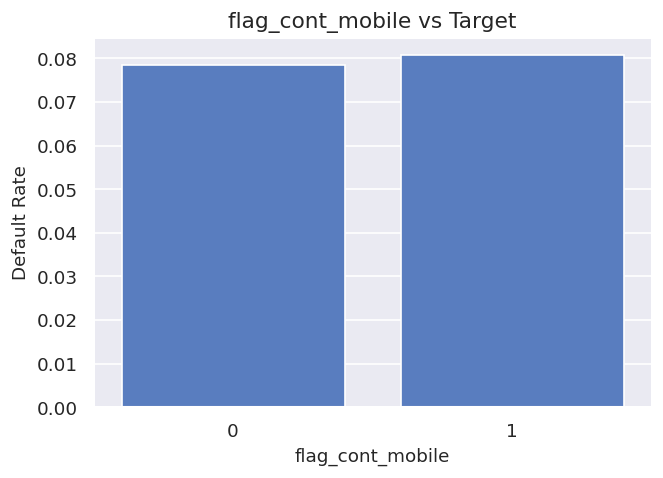

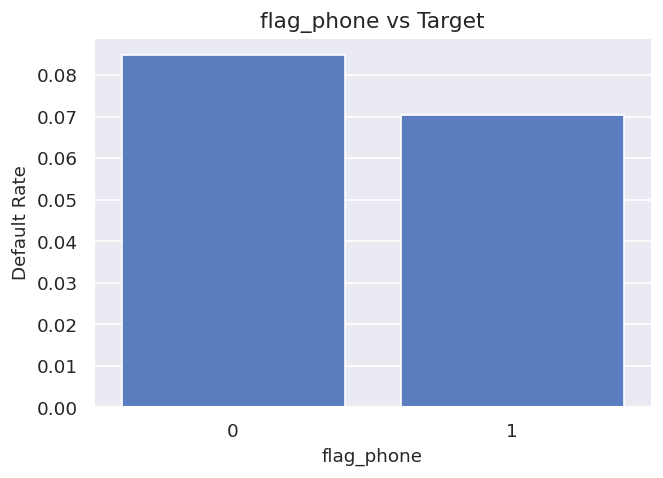

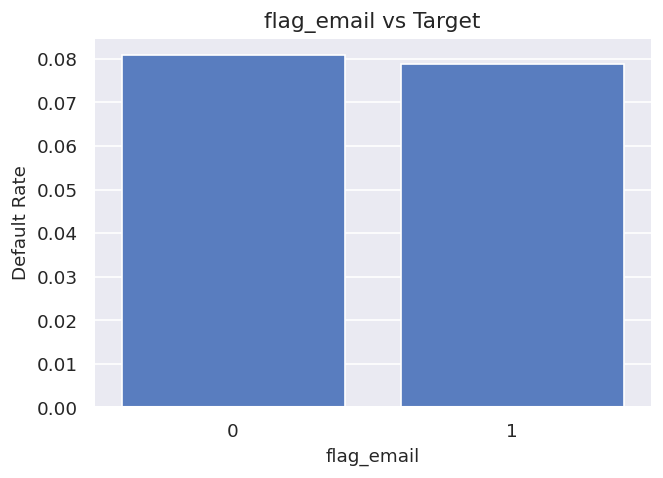

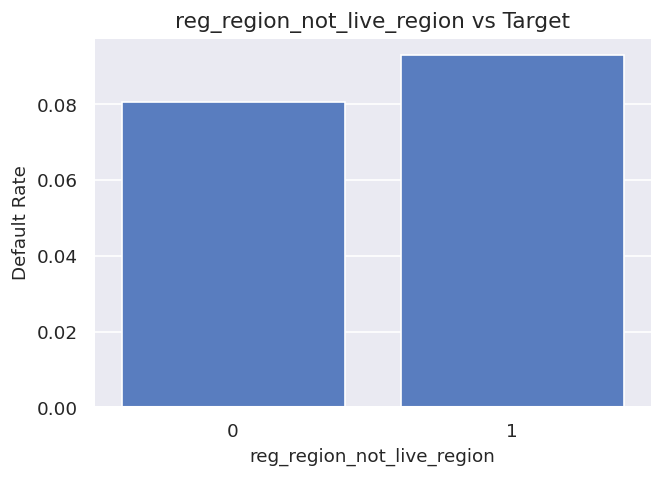

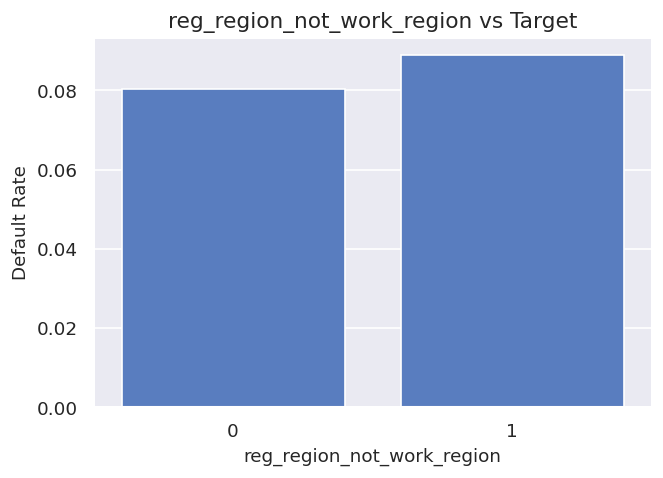

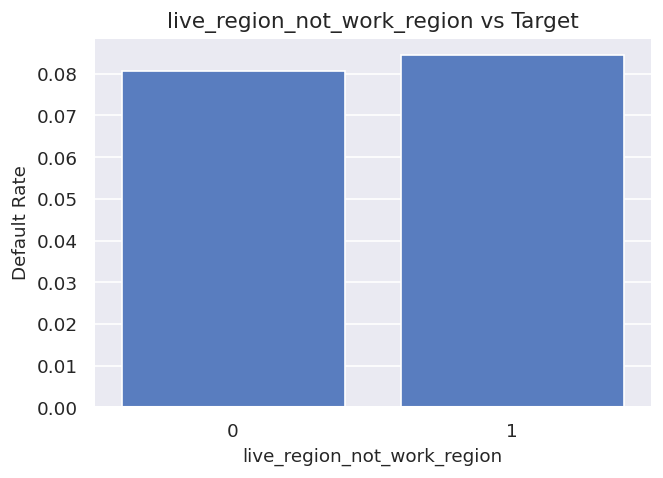

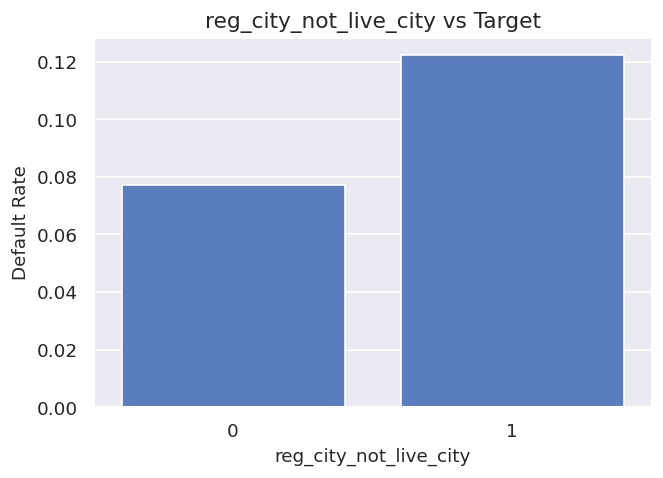

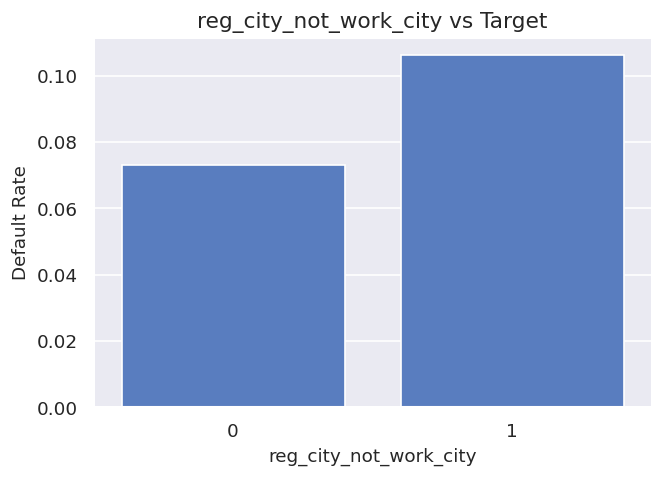

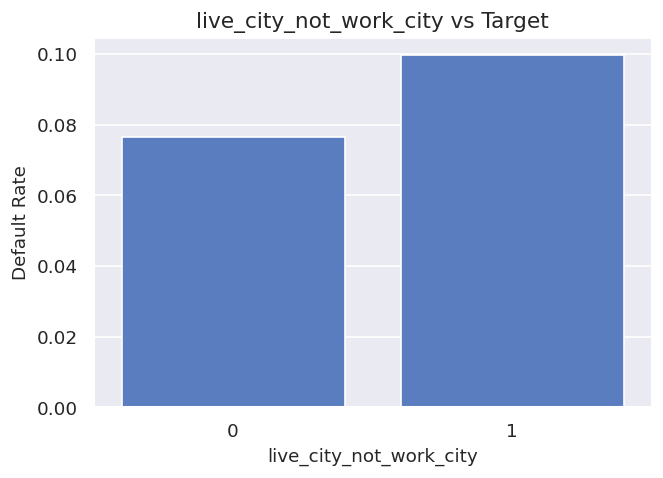

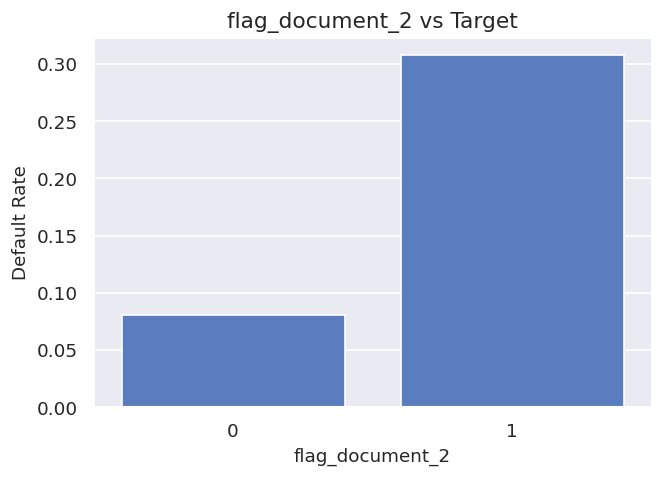

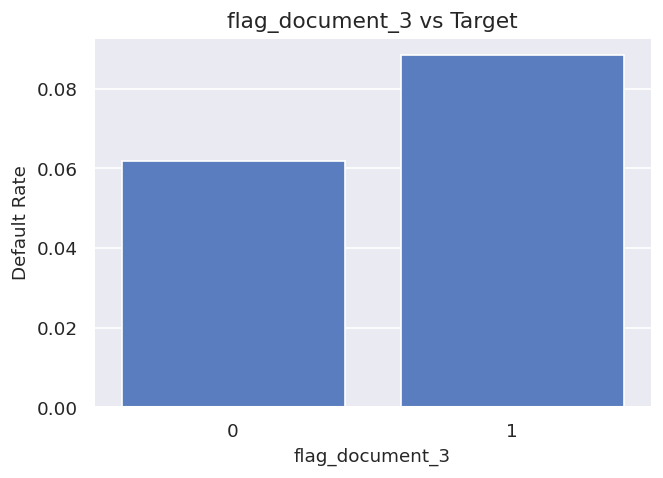

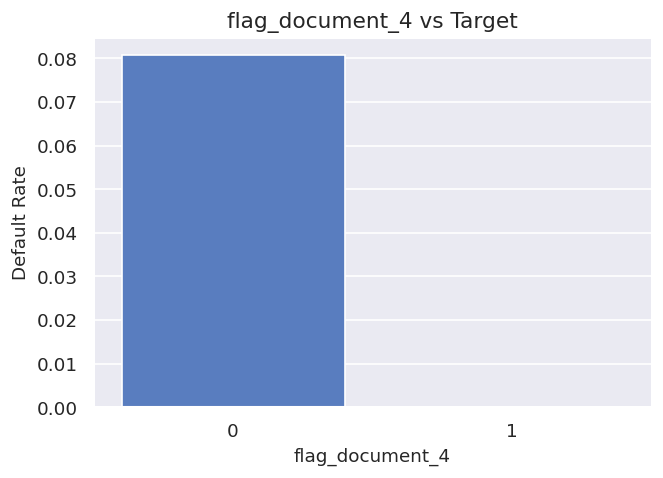

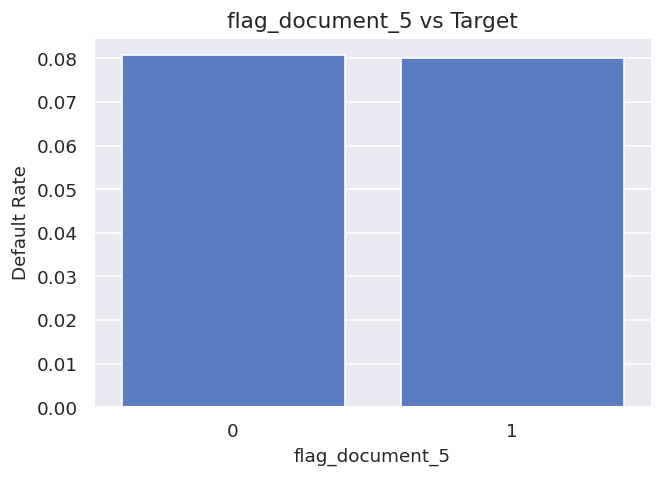

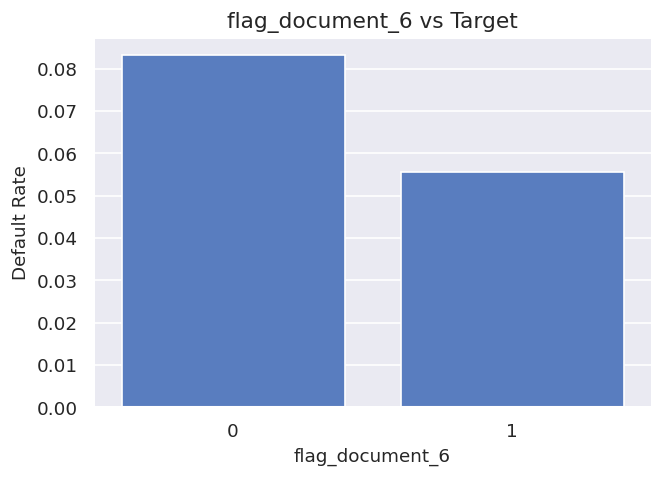

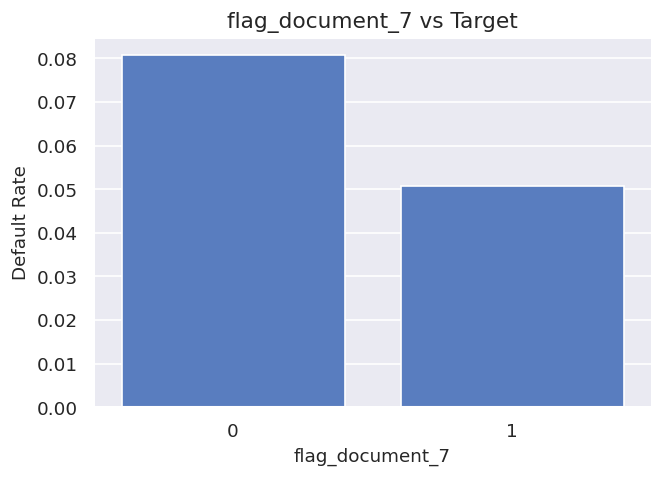

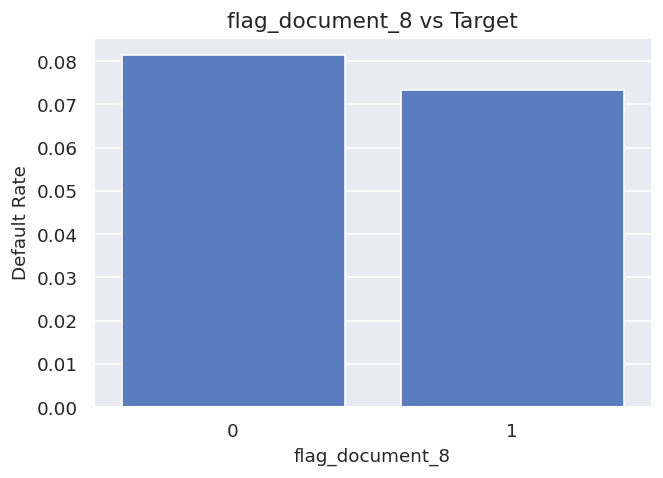

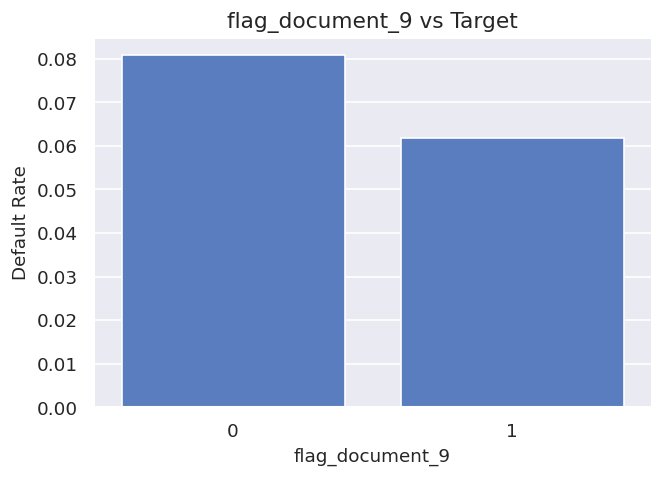

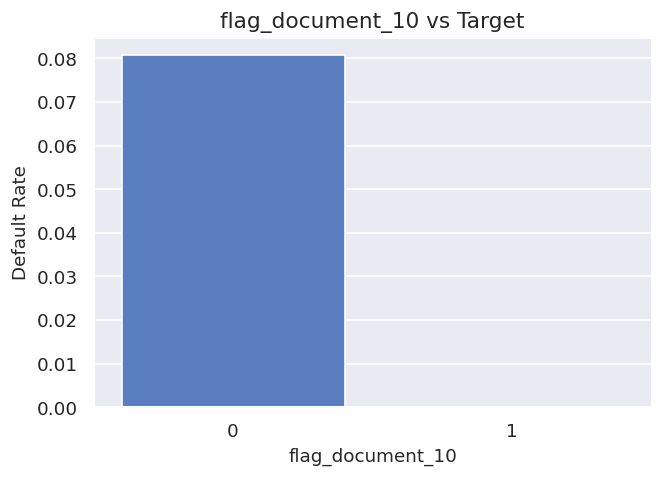

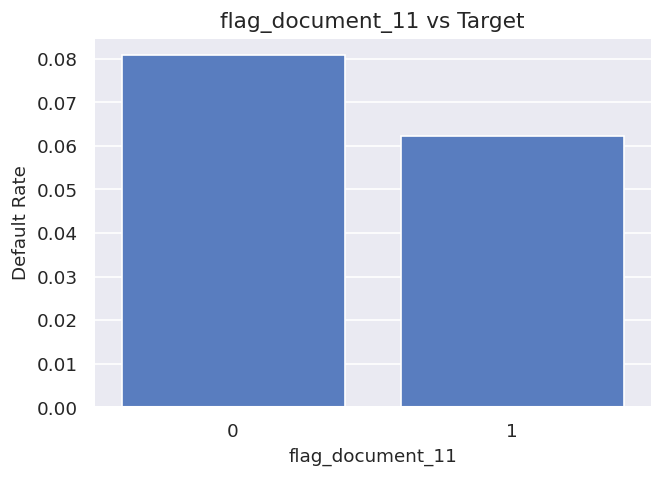

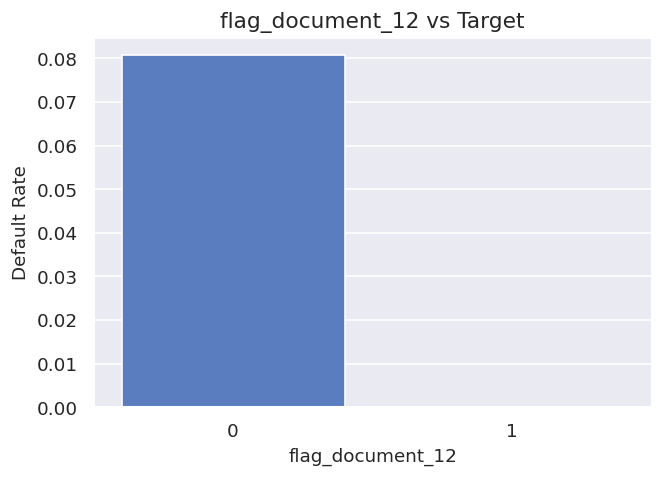

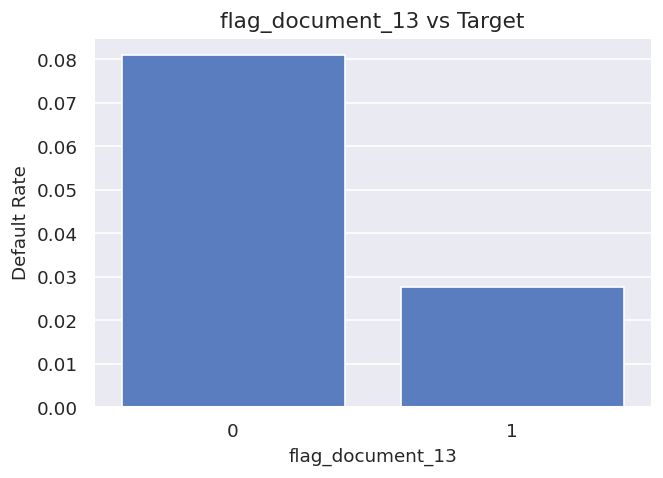

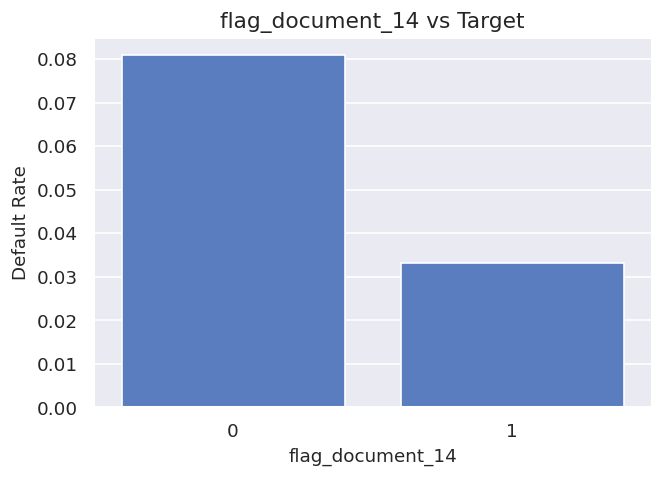

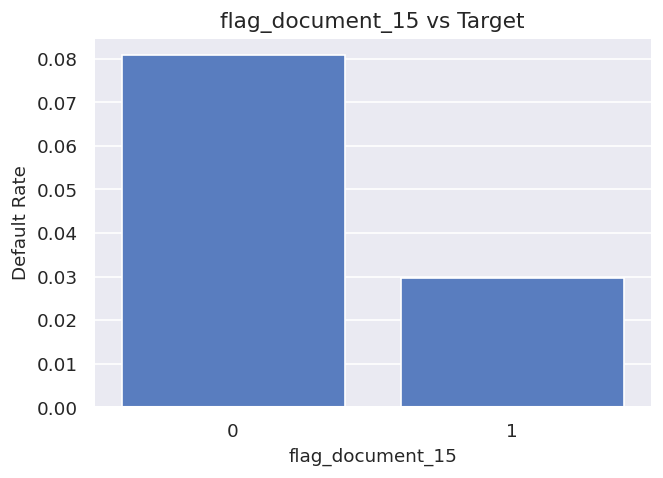

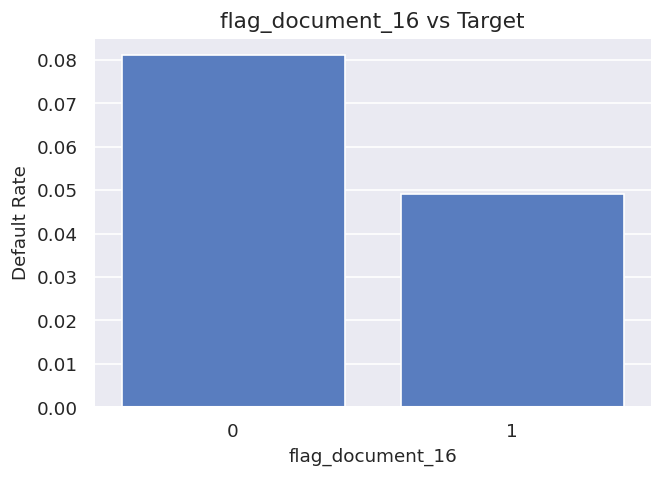

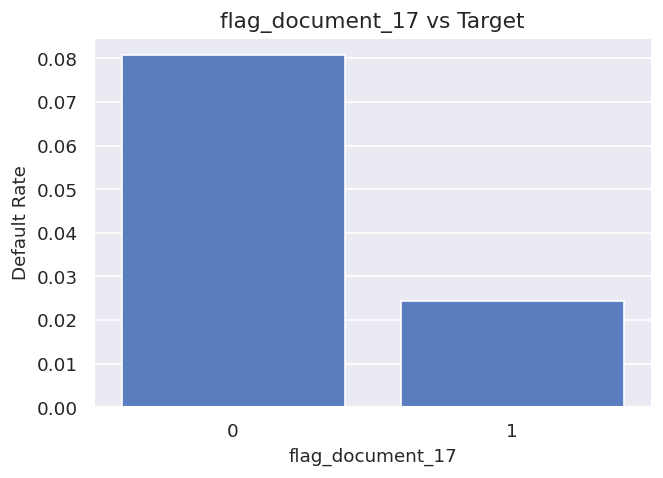

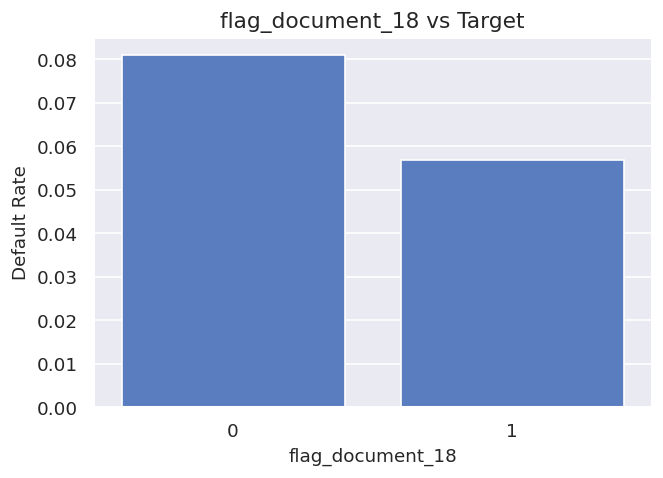

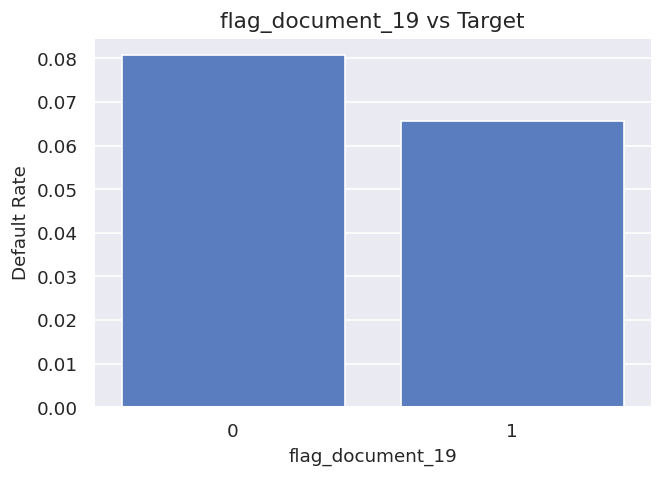

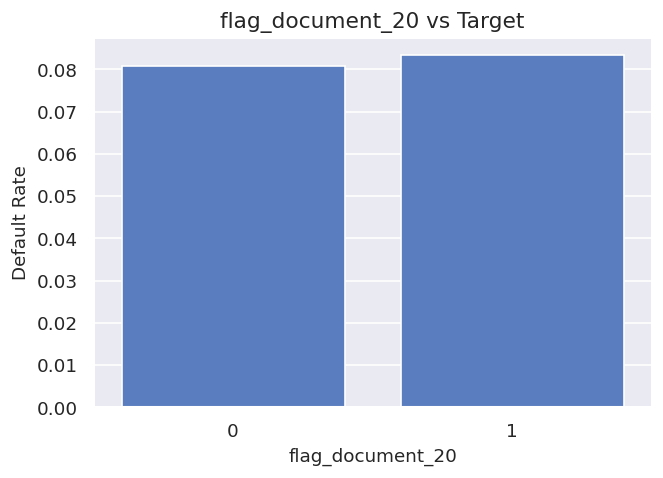

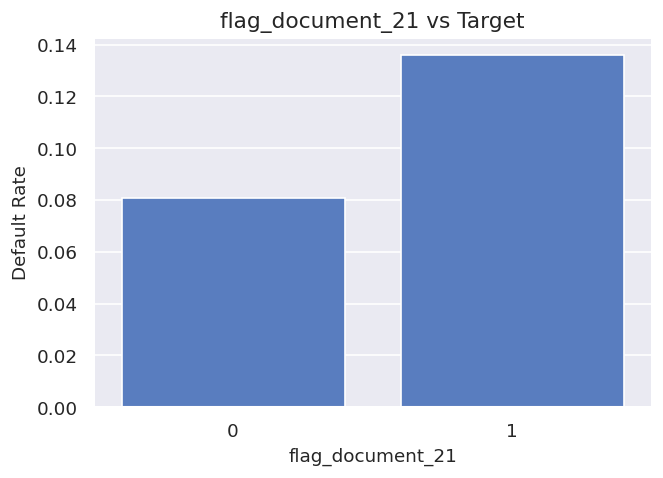

In [36]:
for col in binary_cols:

    plt.figure(figsize=(6, 4))

    sns.barplot(
        x=df[col].fillna('Missing'),
        y=df['target'],
        estimator='mean',
        errorbar=None
    )

    plt.title(f'{col} vs Target')
    plt.xlabel(col)
    plt.ylabel('Default Rate')

    plt.show()

###Observation:
1. Some features have imbalance category distribution such that prescence of that minority category has no impact on target.

2. Categories in some features have comparable default rate.

In [37]:
remove_features = ['flag_mobil','flag_cont_mobile','flag_email','live_region_not_work_region','flag_document_4','flag_document_5','flag_document_10','flag_document_12','flag_document_20']

In [38]:
df.drop(columns=remove_features, inplace=True)

## Distribution Analysis

Let's analyse distributions of some important financial features

In [39]:
df[numerical_cols].columns

Index(['cnt_children', 'amt_income_total', 'amt_credit', 'amt_annuity',
       'amt_goods_price', 'region_population_relative', 'age_years',
       'employment_years', 'registration_years', 'id_publish_years',
       'own_car_age', 'cnt_fam_members', 'region_rating_client',
       'region_rating_client_w_city', 'hour_appr_process_start',
       'ext_source_1', 'ext_source_2', 'ext_source_3', 'apartments_avg',
       'basementarea_avg', 'years_beginexpluatation_avg', 'years_build_avg',
       'commonarea_avg', 'elevators_avg', 'entrances_avg', 'floorsmax_avg',
       'floorsmin_avg', 'landarea_avg', 'livingapartments_avg',
       'livingarea_avg', 'nonlivingapartments_avg', 'nonlivingarea_avg',
       'apartments_mode', 'basementarea_mode', 'years_beginexpluatation_mode',
       'years_build_mode', 'commonarea_mode', 'elevators_mode',
       'entrances_mode', 'floorsmax_mode', 'floorsmin_mode', 'landarea_mode',
       'livingapartments_mode', 'livingarea_mode', 'nonlivingapartments_mode

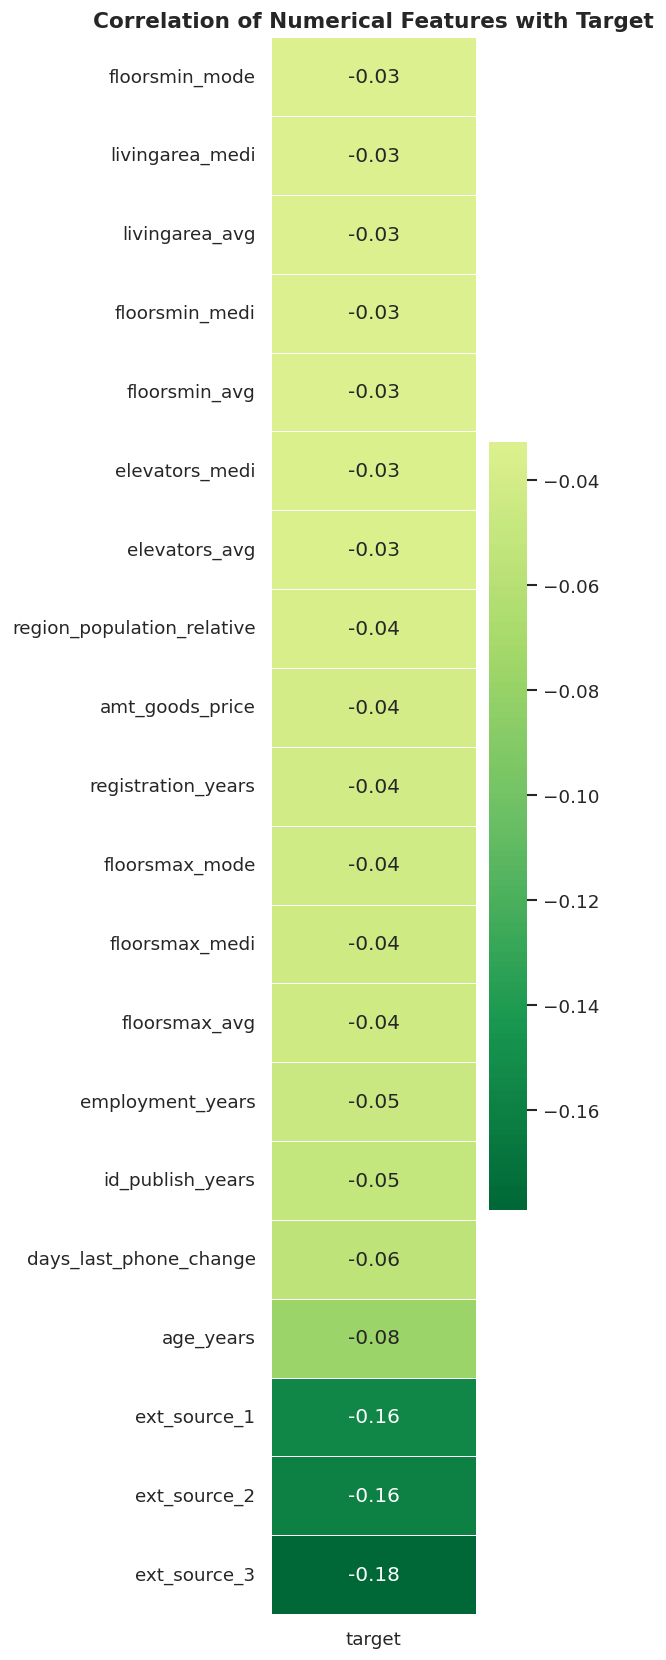

In [40]:
# correlation heatmap of numerical features with target

num_cols = df.select_dtypes(include='number').columns.tolist()
corr_with_target = df[num_cols].corr()[['target']].drop('target').sort_values('target', ascending=False).tail(20)

plt.figure(figsize=(5, 14))
sns.heatmap(corr_with_target, annot=True, fmt='.2f', cmap='RdYlGn_r', center=0,
            linewidths=0.5, cbar_kws={'shrink': 0.6})
plt.title('Correlation of Numerical Features with Target', fontweight='bold')
plt.tight_layout()
plt.show()

** Here we can oberve that ext_source columns are highly correlated with target

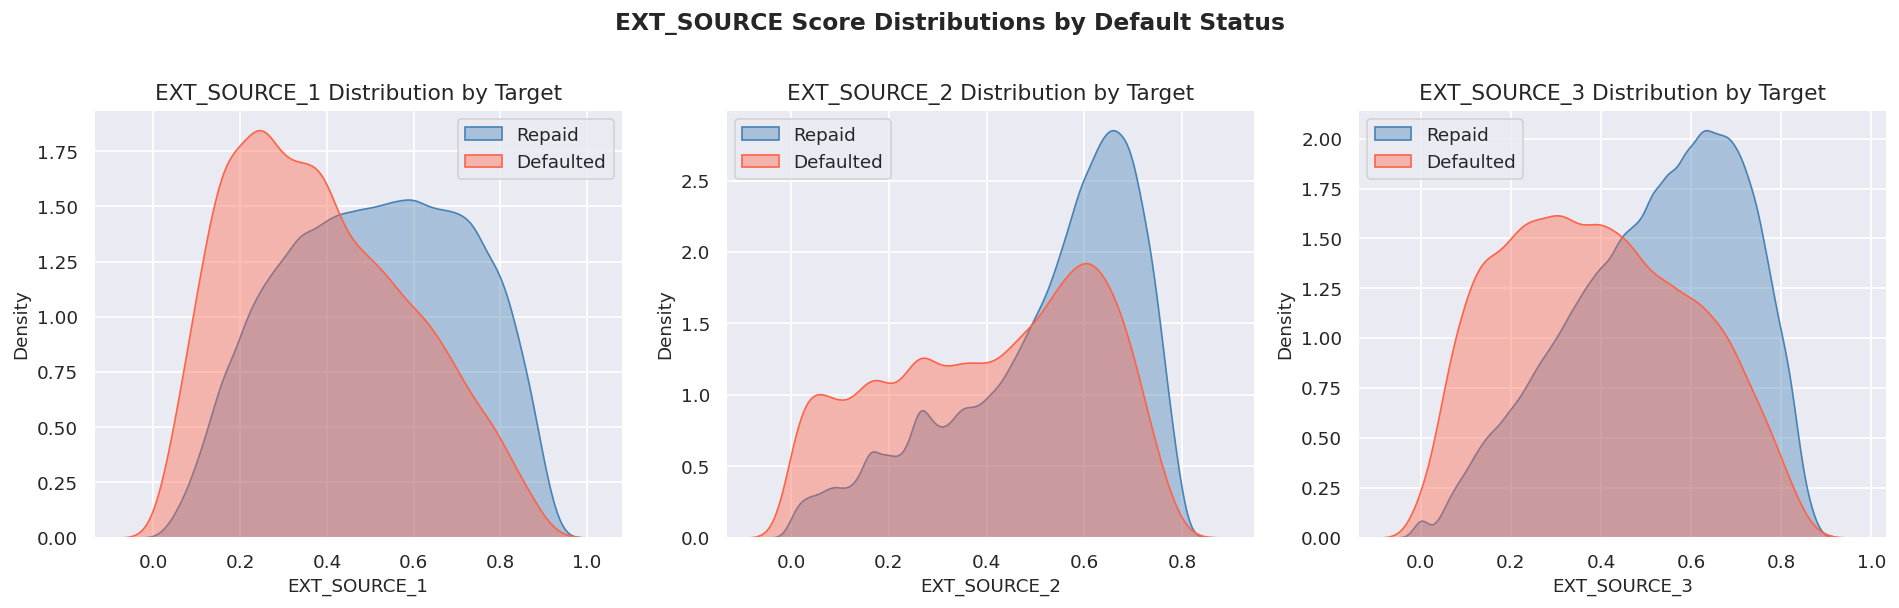

In [41]:
# distribution of ext_source features split by default status

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
ext_cols = ['ext_source_1', 'ext_source_2', 'ext_source_3']

for ax, col in zip(axes, ext_cols):
    for target_val, color, label in [(0, 'steelblue', 'Repaid'), (1, 'tomato', 'Defaulted')]:
        sns.kdeplot(df.loc[df['target'] == target_val, col], ax=ax,
                    fill=True, alpha=0.4, color=color, label=label)
    ax.set_title(f'{col.upper()} Distribution by Target')
    ax.set_xlabel(col.upper())
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('EXT_SOURCE Score Distributions by Default Status', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

####**OBSERVATION**

1. All three EXT_SOURCE features show Defaulted skewing toward lower scores than Repaid, with EXT_SOURCE_2 showing the clearest separation and EXT_SOURCE_1 the weakest.
2. All three features overlap heavily in the mid-range (roughly 0.3-0.6), so none of them cleanly separates defaulters from repayers on its own

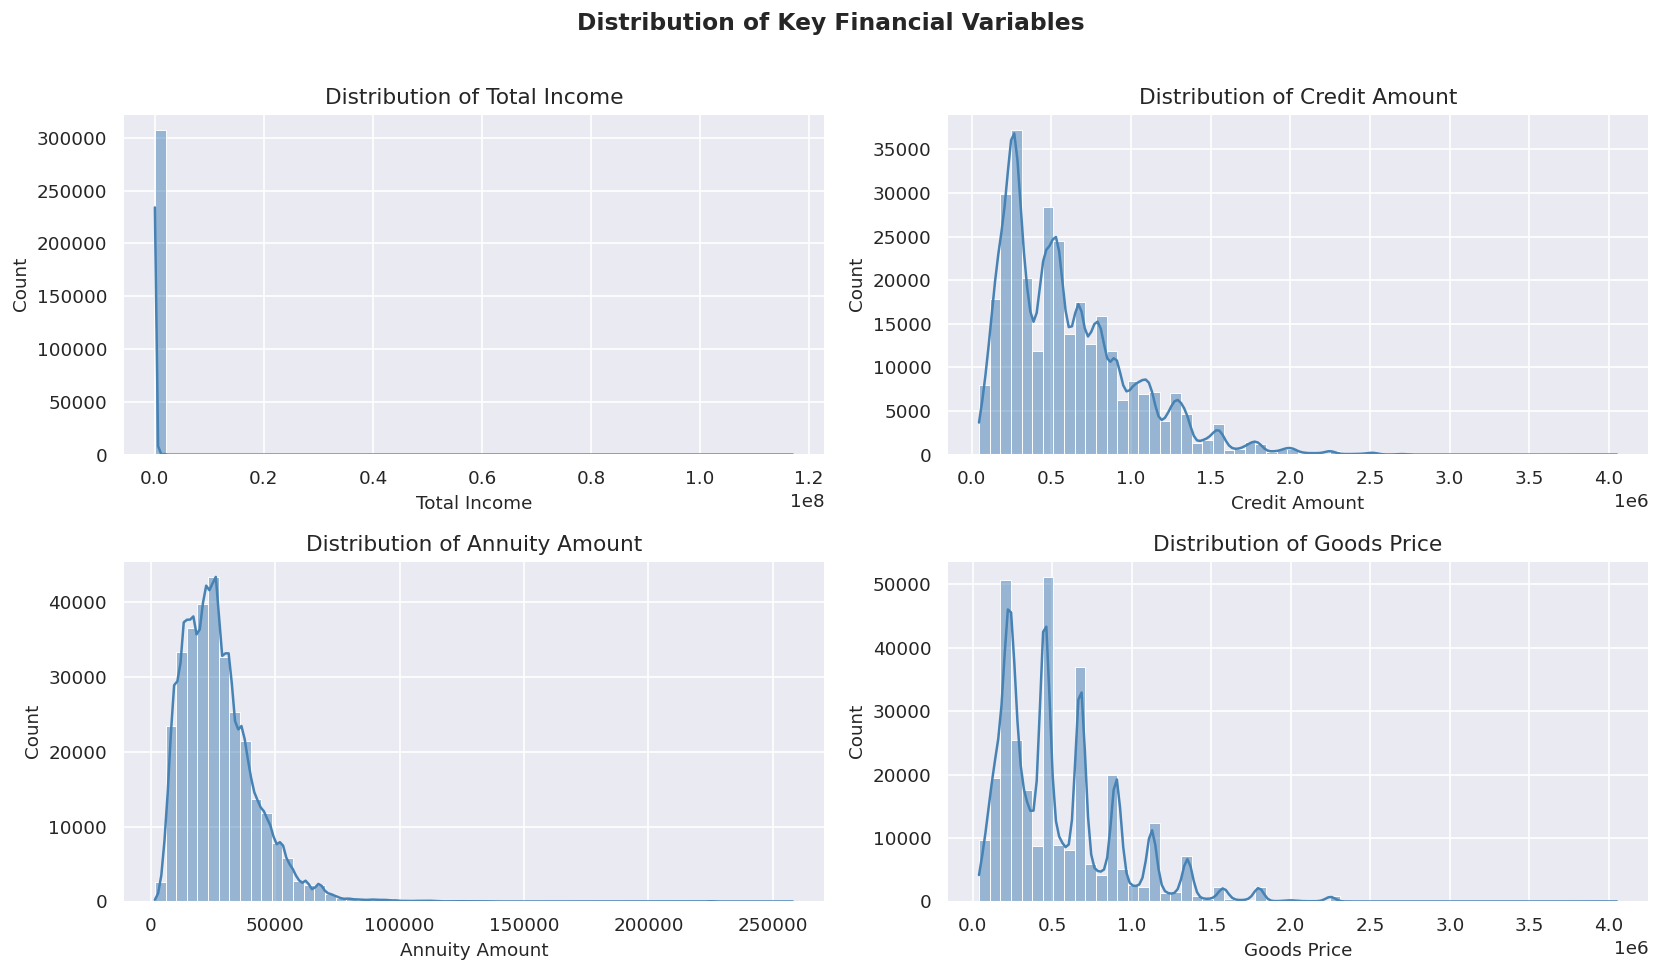

In [42]:
# distribution plots for key loan amount and income columns

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
cols = ['amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price']
titles = ['Total Income', 'Credit Amount', 'Annuity Amount', 'Goods Price']

for ax, col, title in zip(axes.flatten(), cols, titles):
    sns.histplot(df[col], bins=60, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Count')

plt.suptitle('Distribution of Key Financial Variables', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**OBSERVATION**

Income is severely right-skewed with most applicants earning below ₹200K, while credit amount and goods price show distinct multi-modal spikes likely reflecting standardized loan product tiers.
All four variables carry extreme outliers that will compress the box plots and distort model training — Winsorization is required before the Construct stage.

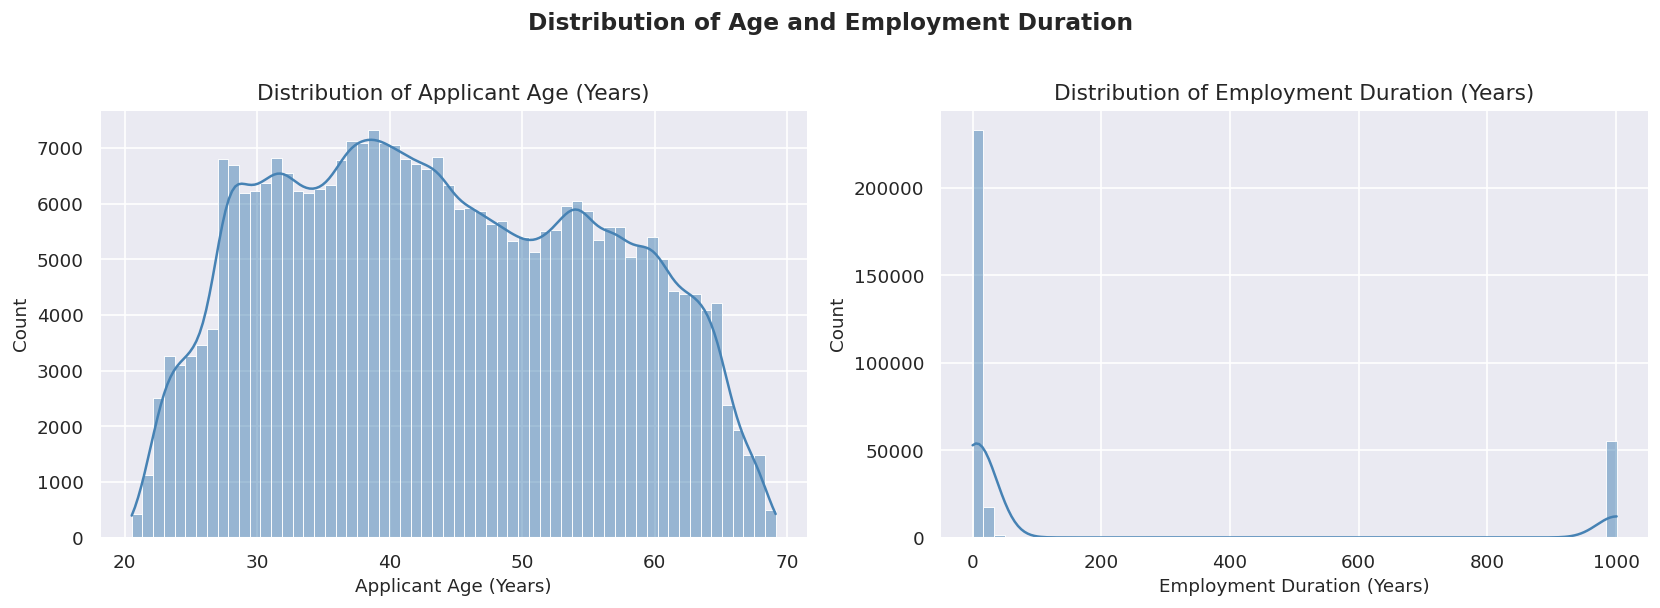

In [43]:
# distribution plots for age and employment years

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cols = ['age_years', 'employment_years']
titles = ['Applicant Age (Years)', 'Employment Duration (Years)']

for ax, col, title in zip(axes, cols, titles):
    sns.histplot(df[col], bins=60, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Count')

plt.suptitle('Distribution of Age and Employment Duration', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**OBSERVATION**

Applicant age peaks around 35–40 years with a secondary concentration at 50–60, indicating the portfolio spans both early-career and pre-retirement borrowers.
Employment duration is sharply right-skewed with most applicants clustered under 5 years in their current job — the spike near zero flags a meaningful share of very recently employed applicants who carry elevated risk.

###OUTLIER ANALYSIS

In [44]:
# outlier analysis for continious numerical and financial features
outlier_cols = ['amt_income_total','amt_credit','amt_annuity','amt_goods_price','age_years','employment_years','own_car_age']

In [45]:
df_numerical = df[outlier_cols]
Q1 = df_numerical.quantile(0.25)
Q3 = df_numerical.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (df_numerical < lower_bound) |
    (df_numerical > upper_bound)
).sum()

outlier_percentage = (
    outlier_count / len(df_numerical) * 100
)

outlier_summary = pd.DataFrame({
    'column_name': df_numerical.columns,
    'outlier_count': outlier_count,
    'outlier_percentage': outlier_percentage
}).sort_values(
    'outlier_percentage',
    ascending=False
)

outlier_summary

,column_name,outlier_count,outlier_percentage
employment_years,employment_years,56357,18.326824
amt_goods_price,amt_goods_price,14728,4.789422
amt_income_total,amt_income_total,14035,4.564064
amt_annuity,amt_annuity,7504,2.440238
amt_credit,amt_credit,6562,2.133907
own_car_age,own_car_age,4932,1.603845
age_years,age_years,0,0.000000


These columns have outliers so we can use techniques like winsorization to cap outliers at 1st and 99th percentile.
But firstly we also have to examine if those extreme values are possible for that particular feature.They may have some impact on target.

In [46]:
df_numerical.min()

,0
amt_income_total,25650.000000
amt_credit,45000.000000
amt_annuity,1615.500000
amt_goods_price,40500.000000
age_years,20.517808
employment_years,0.000000
own_car_age,0.000000


These values seems quite normal and possible.

In [47]:
df_numerical.max()

,0
amt_income_total,1.170000e+08
amt_credit,4.050000e+06
amt_annuity,2.580255e+05
amt_goods_price,4.050000e+06
age_years,6.912055e+01
employment_years,1.000666e+03
own_car_age,9.100000e+01


**Observation:**

Here employment years cannot be 1000 years and car age as 91 years also seems abnormal.So we can apply winsorization here.But firstly we have to do train test split.

**CLASS IMBALANCE ANALYSIS**

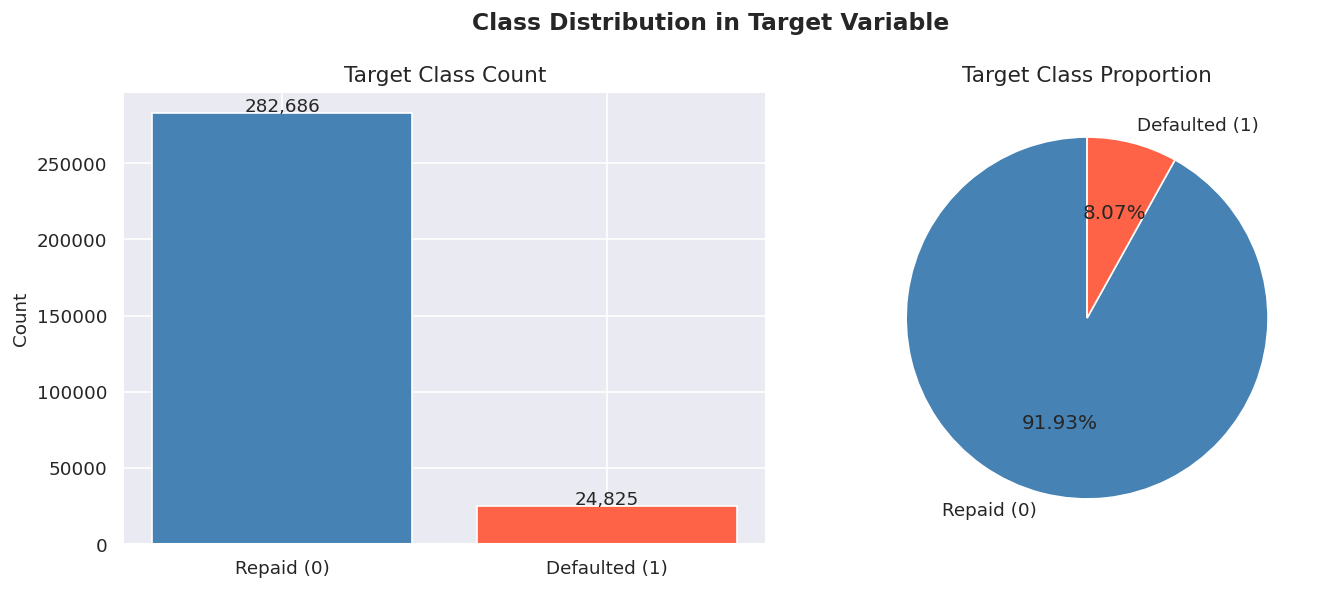

In [48]:
# visualize class imbalance in the target variable

target_counts = df['target'].value_counts()
target_pct = df['target'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Repaid (0)', 'Defaulted (1)'], target_counts.values,
            color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Target Class Count')
axes[0].set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontsize=11)

axes[1].pie(target_pct.values, labels=['Repaid (0)', 'Defaulted (1)'],
            autopct='%1.2f%%', colors=['steelblue', 'tomato'], startangle=90)
axes[1].set_title('Target Class Proportion')

plt.suptitle('Class Distribution in Target Variable', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#####**OBSERVATION:**



*   At 91.93% vs 8.07%, the dataset presents an ~11:1 class imbalance — a model trained naively on this distribution would achieve high accuracy simply by predicting repaid for every applicant while missing nearly all actual defaults.
*   This makes accuracy a meaningless metric for this problem; ROC-AUC and Recall on the minority class are the only evaluation metrics that reflect real-world model utility.




###TRAIN TEST SPLITTING

In [49]:
# separate features and target variable

X = df.drop(columns=['target'])
y = df['target']
print(f"features shape: {X.shape}")
print(f"target shape: {y.shape}")

features shape: (307511, 110)
target shape: (307511,)


In [50]:
# split into 80% temp and 20% test (stratified)

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"temp set: {X_temp.shape} | test set: {X_test.shape}")

temp set: (246008, 110) | test set: (61503, 110)


In [51]:
# split temp into 80% train (64%) and 20% validation (16%) (stratified)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, random_state=42, stratify=y_temp
)
print(f"train: {X_train.shape} | val: {X_val.shape} | test: {X_test.shape}")

train: (196806, 110) | val: (49202, 110) | test: (61503, 110)


In [52]:
# confirm target distribution is preserved across all three splits

for name, y_split in [('train', y_train), ('val', y_val), ('test', y_test)]:
    default_rate = y_split.mean() * 100
    print(f"{name} default rate: {default_rate:.2f}%")

train default rate: 8.07%
val default rate: 8.07%
test default rate: 8.07%


##FEATURE ENGINEERING

In [53]:
# engineer credit, annuity, and income ratio features
# engineer ext_source mean and min aggregate features
for data in [X_train, X_val, X_test]:
    data['credit_income_ratio'] = data['amt_credit'] / (data['amt_income_total'] + 1)
    data['annuity_income_ratio'] = data['amt_annuity'] / (data['amt_income_total'] + 1)
    data['credit_goods_ratio'] = data['amt_credit'] / (data['amt_goods_price'] + 1)
    data['income_per_person'] = data['amt_income_total'] / (data['cnt_fam_members'] + 1)

    data['ext_source_mean'] = data[
        ['ext_source_1', 'ext_source_2', 'ext_source_3']
    ].mean(axis=1)

    data['ext_source_min'] = data[
        ['ext_source_1', 'ext_source_2', 'ext_source_3']
    ].min(axis=1)

In [54]:
property_groups = {
    'apartments': [
        'apartments_avg', 'apartments_medi', 'apartments_mode'
    ],
    'basementarea': [
        'basementarea_avg', 'basementarea_medi', 'basementarea_mode'
    ],
    'commonarea': [
        'commonarea_avg', 'commonarea_medi', 'commonarea_mode'
    ],
    'elevators': [
        'elevators_avg', 'elevators_medi', 'elevators_mode'
    ],
    'entrances': [
        'entrances_avg', 'entrances_medi', 'entrances_mode'
    ],
    'floorsmax': [
        'floorsmax_avg', 'floorsmax_medi', 'floorsmax_mode'
    ],
    'floorsmin': [
        'floorsmin_avg', 'floorsmin_medi', 'floorsmin_mode'
    ],
    'landarea': [
        'landarea_avg', 'landarea_medi', 'landarea_mode'
    ],
    'livingapartments': [
        'livingapartments_avg', 'livingapartments_medi', 'livingapartments_mode'
    ],
    'livingarea': [
        'livingarea_avg', 'livingarea_medi', 'livingarea_mode'
    ],
    'nonlivingapartments': [
        'nonlivingapartments_avg',
        'nonlivingapartments_medi',
        'nonlivingapartments_mode'
    ],
    'nonlivingarea': [
        'nonlivingarea_avg',
        'nonlivingarea_medi',
        'nonlivingarea_mode'
    ],
    'years_beginexpluatation': [
        'years_beginexpluatation_avg',
        'years_beginexpluatation_medi',
        'years_beginexpluatation_mode'
    ],
    'years_build': [
        'years_build_avg',
        'years_build_medi',
        'years_build_mode'
    ]
}

In [55]:
for new_col, cols in property_groups.items():

    X_train[new_col + '_combined'] = X_train[cols].mean(axis=1)
    X_val[new_col + '_combined'] = X_val[cols].mean(axis=1)
    X_test[new_col + '_combined'] = X_test[cols].mean(axis=1)

In [56]:
cols_to_drop = [
    col
    for cols in property_groups.values()
    for col in cols
]

X_train.drop(columns=cols_to_drop, inplace=True)
X_val.drop(columns=cols_to_drop, inplace=True)
X_test.drop(columns=cols_to_drop, inplace=True)

In [57]:
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Train shape: (196806, 88)
Validation shape: (49202, 88)
Test shape: (61503, 88)


In [58]:
cols_to_drop = [
    'obs_60_cnt_social_circle',
    'def_30_cnt_social_circle'
]

X_train.drop(columns=cols_to_drop, inplace=True)
X_val.drop(columns=cols_to_drop, inplace=True)
X_test.drop(columns=cols_to_drop, inplace=True)

In [59]:
df[numerical_cols].nunique().sort_values()

,0
region_rating_client,3
region_rating_client_w_city,3
amt_req_credit_bureau_hour,5
def_60_cnt_social_circle,9
amt_req_credit_bureau_week,9
...,...
amt_annuity,13672
registration_years,15688
age_years,17460
ext_source_1,114584


###MEDIAN IMPUTATION

In [60]:
numerical_cols = [
    col for col in X_train.columns
    if col not in binary_cols
    and X_train[col].dtype in ['int64', 'float64']
]

In [61]:
for data in [X_train, X_val, X_test]:
    data.loc[data['employment_years'] > 100, 'employment_years'] = np.nan

In [62]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy='median')

X_train[numerical_cols] = num_imputer.fit_transform(
    X_train[numerical_cols]
)

X_val[numerical_cols] = num_imputer.transform(
    X_val[numerical_cols]
)

X_test[numerical_cols] = num_imputer.transform(
    X_test[numerical_cols]
)

###CATEGORICAL IMPUTATION

In [63]:
categorical_cols = [
    col for col in X_train.columns
    if X_train[col].dtype == 'object'
]

In [64]:
print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

Categorical columns: 15
['name_contract_type', 'code_gender', 'flag_own_car', 'flag_own_realty', 'name_type_suite', 'name_income_type', 'name_education_type', 'name_family_status', 'name_housing_type', 'occupation_type', 'weekday_appr_process_start', 'organization_type', 'housetype_mode', 'wallsmaterial_mode', 'emergencystate_mode']


In [65]:
cat_imputer = SimpleImputer(
    strategy='constant',
    fill_value='Missing'
)

X_train[categorical_cols] = cat_imputer.fit_transform(
    X_train[categorical_cols]
)

X_val[categorical_cols] = cat_imputer.transform(
    X_val[categorical_cols]
)

X_test[categorical_cols] = cat_imputer.transform(
    X_test[categorical_cols]
)

In [66]:
print("Train categorical missing:",
      X_train[categorical_cols].isna().sum().sum())

print("Validation categorical missing:",
      X_val[categorical_cols].isna().sum().sum())

print("Test categorical missing:",
      X_test[categorical_cols].isna().sum().sum())

Train categorical missing: 0
Validation categorical missing: 0
Test categorical missing: 0


In [67]:
binary_cols = [
    col for col in binary_cols
    if col in X_train.columns
]

In [68]:
print("Numerical:", len(numerical_cols))
print("Categorical:", len(categorical_cols))
print("Binary:", len(binary_cols))

Numerical: 48
Categorical: 15
Binary: 23


In [69]:
X_train[binary_cols].isnull().sum().sum()

np.int64(0)

There are no missing values in binary columns.

####Winsorization

In [70]:
# Continuous/skewed columns to winsorize
skewed_cols = [
    col for col in outlier_cols
    if col != 'age_years'
]

# Calculate caps ONLY from training data
lower_caps = X_train[skewed_cols].quantile(0.01)
upper_caps = X_train[skewed_cols].quantile(0.99)

# Apply the same caps to train, validation and test
X_train[skewed_cols] = X_train[skewed_cols].clip(
    lower=lower_caps,
    upper=upper_caps,
    axis=1
)

X_val[skewed_cols] = X_val[skewed_cols].clip(
    lower=lower_caps,
    upper=upper_caps,
    axis=1
)

X_test[skewed_cols] = X_test[skewed_cols].clip(
    lower=lower_caps,
    upper=upper_caps,
    axis=1
)

print(
    "Winsorization complete — clipped at 1st and 99th percentile for:",
    skewed_cols
)

Winsorization complete — clipped at 1st and 99th percentile for: ['amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price', 'employment_years', 'own_car_age']


###Boxplot

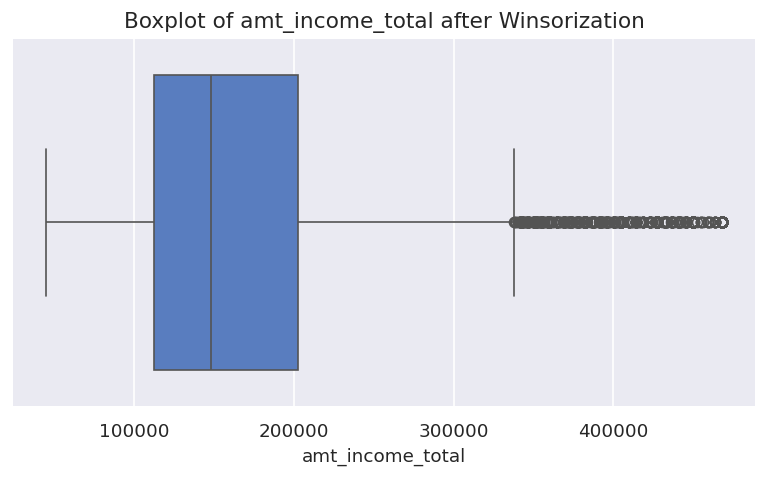

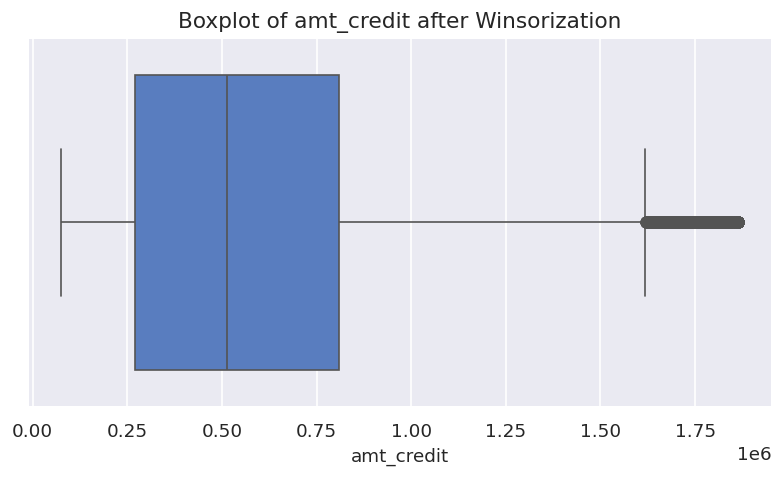

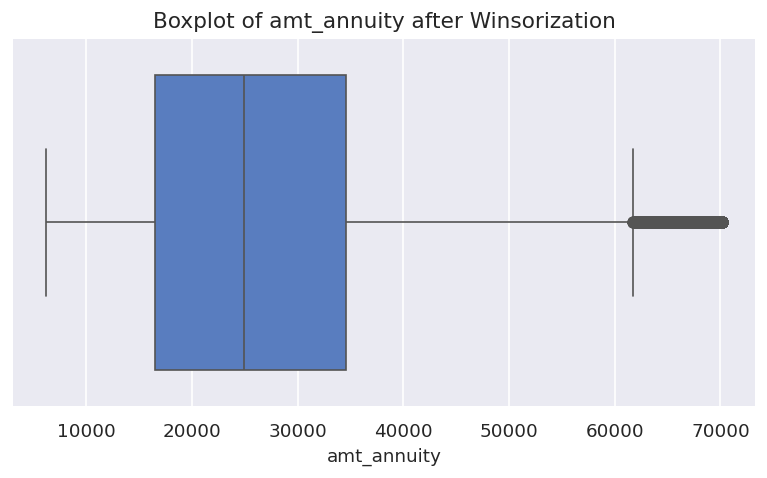

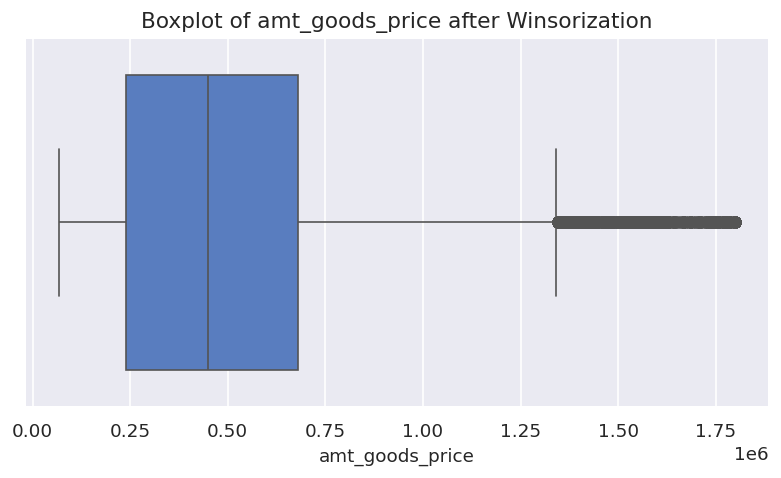

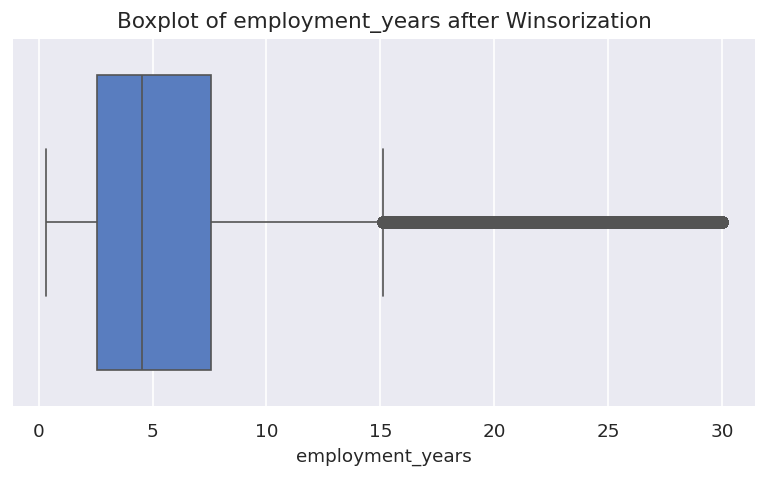

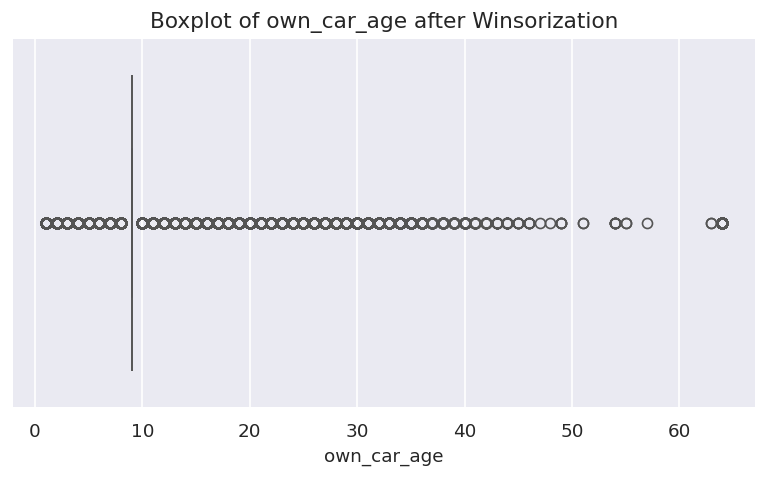

In [71]:
for col in skewed_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=X_train[col])
    plt.title(f'Boxplot of {col} after Winsorization')
    plt.xlabel(col)
    plt.show()

##CATEGORICAL ENCODING

In [72]:
print(categorical_cols)
print(len(categorical_cols))

['name_contract_type', 'code_gender', 'flag_own_car', 'flag_own_realty', 'name_type_suite', 'name_income_type', 'name_education_type', 'name_family_status', 'name_housing_type', 'occupation_type', 'weekday_appr_process_start', 'organization_type', 'housetype_mode', 'wallsmaterial_mode', 'emergencystate_mode']
15


In [73]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_val_cat = encoder.transform(X_val[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

In [74]:
encoded_cols = encoder.get_feature_names_out(categorical_cols)

print(len(encoded_cols))

141


In [75]:
#Convert into dataframes
X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoded_cols,
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    X_val_cat,
    columns=encoded_cols,
    index=X_val.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=encoded_cols,
    index=X_test.index
)

In [76]:
X_train_num = X_train.drop(columns=categorical_cols)
X_val_num = X_val.drop(columns=categorical_cols)
X_test_num = X_test.drop(columns=categorical_cols)

In [77]:
#Concatenation
X_train = pd.concat([X_train_num, X_train_cat], axis=1)
X_val = pd.concat([X_val_num, X_val_cat], axis=1)
X_test = pd.concat([X_test_num, X_test_cat], axis=1)

In [78]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(196806, 212)
(49202, 212)
(61503, 212)


####Feature Scaling:

In [79]:
scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

X_val[numerical_cols] = scaler.transform(
    X_val[numerical_cols]
)

X_test[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)

In [80]:
#Verify
print(X_train[numerical_cols].mean().round(2))
print(X_train[numerical_cols].std().round(2))

cnt_children                        0.0
amt_income_total                   -0.0
amt_credit                          0.0
amt_annuity                         0.0
amt_goods_price                    -0.0
region_population_relative         -0.0
age_years                           0.0
employment_years                   -0.0
registration_years                 -0.0
id_publish_years                    0.0
own_car_age                         0.0
cnt_fam_members                    -0.0
region_rating_client               -0.0
region_rating_client_w_city         0.0
hour_appr_process_start            -0.0
ext_source_1                        0.0
ext_source_2                       -0.0
ext_source_3                        0.0
totalarea_mode                     -0.0
obs_30_cnt_social_circle           -0.0
def_60_cnt_social_circle            0.0
days_last_phone_change             -0.0
amt_req_credit_bureau_hour         -0.0
amt_req_credit_bureau_day           0.0
amt_req_credit_bureau_week         -0.0


####Handling Class Imbalance:

In [81]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [82]:
#Verify
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
target
0    180918
1     15888
Name: count, dtype: int64

After SMOTE:
target
0    180918
1    180918
Name: count, dtype: int64


In [83]:
print("X_train before SMOTE:", X_train.shape)
print("X_train after SMOTE :", X_train_smote.shape)

print("y_train before SMOTE:", y_train.shape)
print("y_train after SMOTE :", y_train_smote.shape)

X_train before SMOTE: (196806, 212)
X_train after SMOTE : (361836, 212)
y_train before SMOTE: (196806,)
y_train after SMOTE : (361836,)


##MODEL TRAINING AND EVALUATION

Here we will validate the model by using:
1. SMOTE
2. class_weights

####1. Logistic Regression

In [84]:
#with smote
lr_smote_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('lr', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

param_dist_lr = {
    'lr__C': [0.01, 0.1, 1, 10]
}

lr_smote_search = RandomizedSearchCV(
    lr_smote_pipeline,
    param_distributions=param_dist_lr,
    n_iter=4,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

lr_smote_search.fit(X_train, y_train)

best_lr_smote = lr_smote_search.best_estimator_

y_val_prob_lr_smote = best_lr_smote.predict_proba(X_val)[:, 1]

print("Best Parameters:", lr_smote_search.best_params_)
print("CV ROC-AUC:", lr_smote_search.best_score_)
print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_val_prob_lr_smote))
print("Validation PR-AUC:",
      average_precision_score(y_val, y_val_prob_lr_smote))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'lr__C': 0.01}
CV ROC-AUC: 0.6901900446193697
Validation ROC-AUC: 0.6893978944809109
Validation PR-AUC: 0.1771906457213238


In [85]:
#without smote
lr_weight = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

param_dist_lr_weight = {
    'C': [0.01, 0.1, 1, 10]
}

lr_weight_search = RandomizedSearchCV(
    lr_weight,
    param_distributions=param_dist_lr_weight,
    n_iter=4,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

lr_weight_search.fit(X_train, y_train)

best_lr_weight = lr_weight_search.best_estimator_

y_val_prob_lr_weight = best_lr_weight.predict_proba(X_val)[:, 1]

print("Best Parameters:", lr_weight_search.best_params_)
print("CV ROC-AUC:", lr_weight_search.best_score_)
print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_val_prob_lr_weight))
print("Validation PR-AUC:",
      average_precision_score(y_val, y_val_prob_lr_weight))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'C': 0.01}
CV ROC-AUC: 0.7469258838082876
Validation ROC-AUC: 0.7463831164826347
Validation PR-AUC: 0.22219714328826132


####2. Using Decision Trees

In [86]:
#with smote

dt_smote_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42))
])


param_dist_dt = {
    'dt__max_depth': [3, 5, 7, 10, 15, 20],
    'dt__min_samples_split': [2, 10, 50],
    'dt__min_samples_leaf': [1, 5, 10, 25],
    'dt__criterion': ['gini', 'entropy']
}


dt_smote_search = RandomizedSearchCV(
    dt_smote_pipeline,
    param_distributions=param_dist_dt,
    n_iter=6,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)


dt_smote_search.fit(X_train, y_train)


best_dt_smote = dt_smote_search.best_estimator_

y_val_prob_dt_smote = best_dt_smote.predict_proba(X_val)[:, 1]


print("Best Parameters:", dt_smote_search.best_params_)
print("CV ROC-AUC:", dt_smote_search.best_score_)
print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val, y_val_prob_dt_smote)
)
print(
    "Validation PR-AUC:",
    average_precision_score(y_val, y_val_prob_dt_smote)
)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'dt__min_samples_split': 10, 'dt__min_samples_leaf': 10, 'dt__max_depth': 5, 'dt__criterion': 'gini'}
CV ROC-AUC: 0.6698262670801872
Validation ROC-AUC: 0.667572780077389
Validation PR-AUC: 0.1357953807531657


In [87]:
#without smote
dt_weight = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)


param_dist_dt_weight = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': [2, 10, 50],
    'min_samples_leaf': [1, 5, 10, 25],
    'criterion': ['gini', 'entropy']
}


dt_weight_search = RandomizedSearchCV(
    dt_weight,
    param_distributions=param_dist_dt_weight,
    n_iter=6,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)


dt_weight_search.fit(X_train, y_train)


best_dt_weight = dt_weight_search.best_estimator_

y_val_prob_dt_weight = best_dt_weight.predict_proba(X_val)[:, 1]


print("Best Parameters:", dt_weight_search.best_params_)
print("CV ROC-AUC:", dt_weight_search.best_score_)
print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val, y_val_prob_dt_weight)
)
print(
    "Validation PR-AUC:",
    average_precision_score(y_val, y_val_prob_dt_weight)
)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'min_samples_split': 50, 'min_samples_leaf': 25, 'max_depth': 7, 'criterion': 'entropy'}
CV ROC-AUC: 0.7174396260090656
Validation ROC-AUC: 0.7196841103510554
Validation PR-AUC: 0.19423111876803434


####3. Using Random Forest

In [88]:
#using smote
# ==========================================
# 1. Pipeline: SMOTE + Random Forest
# ==========================================

rf_smote_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])


# ==========================================
# 2. Hyperparameter search space
# ==========================================

param_dist_rf = {
    'rf__n_estimators': [100, 150, 200],
    'rf__max_depth': [10, 15, 20],
    'rf__min_samples_split': [5, 10],
    'rf__min_samples_leaf': [1, 2, 4],
    'rf__max_features': ['sqrt']
}


# ==========================================
# 3. Randomized Search
# ==========================================

rf_smote_search = RandomizedSearchCV(
    estimator=rf_smote_pipeline,
    param_distributions=param_dist_rf,
    n_iter=6,
    cv=2,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)


# ==========================================
# 4. Fit
# ==========================================

rf_smote_search.fit(X_train, y_train)


# ==========================================
# 5. Best parameters
# ==========================================

print("\nBest Parameters:")
print(rf_smote_search.best_params_)

print("\nBest CV ROC-AUC:")
print(rf_smote_search.best_score_)


# ==========================================
# 6. Validation
# ==========================================

best_rf_smote = rf_smote_search.best_estimator_

y_val_prob_rf_smote = best_rf_smote.predict_proba(X_val)[:, 1]

print(
    "\nValidation ROC-AUC:",
    roc_auc_score(y_val, y_val_prob_rf_smote)
)

print(
    "Validation PR-AUC:",
    average_precision_score(y_val, y_val_prob_rf_smote)
)

Fitting 2 folds for each of 6 candidates, totalling 12 fits

Best Parameters:
{'rf__n_estimators': 150, 'rf__min_samples_split': 5, 'rf__min_samples_leaf': 4, 'rf__max_features': 'sqrt', 'rf__max_depth': 20}

Best CV ROC-AUC:
0.7232078105811641

Validation ROC-AUC: 0.7246559656262865
Validation PR-AUC: 0.1852479427662171


In [89]:
#without smote
# ==========================================
# 1. Random Forest with class weighting
# ==========================================

rf_weight = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)


# ==========================================
# 2. Hyperparameter search space
# ==========================================

param_dist_rf_weight = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt']
}


# ==========================================
# 3. Randomized Search
# ==========================================

rf_weight_search = RandomizedSearchCV(
    estimator=rf_weight,
    param_distributions=param_dist_rf_weight,
    n_iter=6,
    cv=2,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)


# ==========================================
# 4. Fit on ORIGINAL training data
# ==========================================

rf_weight_search.fit(X_train, y_train)


# ==========================================
# 5. Best parameters
# ==========================================

print("\nBest Parameters:")
print(rf_weight_search.best_params_)

print("\nBest CV ROC-AUC:")
print(rf_weight_search.best_score_)


# ==========================================
# 6. Validation
# ==========================================

best_rf_weight = rf_weight_search.best_estimator_

y_val_prob_rf_weight = best_rf_weight.predict_proba(X_val)[:, 1]

print(
    "\nValidation ROC-AUC:",
    roc_auc_score(y_val, y_val_prob_rf_weight)
)

print(
    "Validation PR-AUC:",
    average_precision_score(y_val, y_val_prob_rf_weight)
)

Fitting 2 folds for each of 6 candidates, totalling 12 fits

Best Parameters:
{'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'max_depth': None}

Best CV ROC-AUC:
0.7443459269385526

Validation ROC-AUC: 0.7435518450065783
Validation PR-AUC: 0.22163172922182228


####4. Using XGBoost

In [90]:
#with smote
# ==========================================
# 1. Pipeline: SMOTE + XGBoost
# ==========================================

xgb_smote_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        random_state=42,
        n_jobs=-1
    ))
])


# ==========================================
# 2. Hyperparameter search space
# ==========================================

param_dist_xgb = {
    'xgb__n_estimators': [100, 200, 300],
    'xgb__max_depth': [3, 5, 7],
    'xgb__learning_rate': [0.03, 0.05, 0.1],
    'xgb__subsample': [0.8, 1.0],
    'xgb__colsample_bytree': [0.8, 1.0],
    'xgb__min_child_weight': [1, 5, 10]
}


# ==========================================
# 3. Randomized Search
# ==========================================

xgb_smote_search = RandomizedSearchCV(
    estimator=xgb_smote_pipeline,
    param_distributions=param_dist_xgb,
    n_iter=6,
    cv=2,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)


# ==========================================
# 4. Fit on ORIGINAL training data
# ==========================================

xgb_smote_search.fit(X_train, y_train)


# ==========================================
# 5. Best parameters
# ==========================================

print("\nBest Parameters:")
print(xgb_smote_search.best_params_)

print("\nBest CV ROC-AUC:")
print(xgb_smote_search.best_score_)


# ==========================================
# 6. Validation
# ==========================================

best_xgb_smote = xgb_smote_search.best_estimator_

y_val_prob_xgb_smote = best_xgb_smote.predict_proba(X_val)[:, 1]

print(
    "\nValidation ROC-AUC:",
    roc_auc_score(y_val, y_val_prob_xgb_smote)
)

print(
    "Validation PR-AUC:",
    average_precision_score(y_val, y_val_prob_xgb_smote)
)

Fitting 2 folds for each of 6 candidates, totalling 12 fits

Best Parameters:
{'xgb__subsample': 1.0, 'xgb__n_estimators': 300, 'xgb__min_child_weight': 5, 'xgb__max_depth': 5, 'xgb__learning_rate': 0.1, 'xgb__colsample_bytree': 0.8}

Best CV ROC-AUC:
0.7445904227785948

Validation ROC-AUC: 0.7536781737027644
Validation PR-AUC: 0.2337571947505137


In [91]:
#without smote
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative:", negative_count)
print("Positive:", positive_count)
print("scale_pos_weight:", scale_pos_weight)

Negative: 180918
Positive: 15888
scale_pos_weight: 11.387084592145015


In [92]:
xgb_weight = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

In [93]:
param_dist_xgb_weight = {
    'n_estimators': [300, 400, 500, 600,700],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.01, 0.1, 0.5, 1],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.3, 0.5, 1],
    'min_child_weight': [1, 5, 10],
    'reg_lambda': [1, 2, 5, 10]
}


xgb_weight_search = RandomizedSearchCV(
    estimator=xgb_weight,
    param_distributions=param_dist_xgb_weight,
    n_iter=10,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=2
)


xgb_weight_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='auc',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constrain...
                   n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'gamma': [0, 0.1, 0.3, 0.5, 1],
                                        'learning_rate': [0.01, 0.03, 0.05,
                                                          0.08, 0.1],
                                        'max_depth': [3, 4, 5, 6, 7],
                                        'min_child_weight': [1, 5, 10],
                                        'n_estimators': [300, 400, 500, 600,
                                                         700],
                                        'reg_alpha': [0, 0.01, 0.1, 0.5, 1],
                                        'reg_lambda': [1, 2, 5, 10],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='roc_auc', verbose=2)

In [94]:
print("\nBest Parameters:")
print(xgb_weight_search.best_params_)

print("\nBest CV ROC-AUC:")
print(xgb_weight_search.best_score_)


best_xgb_weight = xgb_weight_search.best_estimator_


Best Parameters:
{'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.7}

Best CV ROC-AUC:
0.7568521303353567


In [95]:
y_val_prob_xgb_weight = best_xgb_weight.predict_proba(X_val)[:, 1]

roc_auc_xgb_weight = roc_auc_score(
    y_val,
    y_val_prob_xgb_weight
)

pr_auc_xgb_weight = average_precision_score(
    y_val,
    y_val_prob_xgb_weight
)

print("\nValidation ROC-AUC:", roc_auc_xgb_weight)
print("Validation PR-AUC:", pr_auc_xgb_weight)

y_val_pred_xgb_weight = (y_val_prob_xgb_weight >= 0.5).astype(int)

print("\nClassification Report - XGBoost + Class Weight:")
print(classification_report(y_val, y_val_pred_xgb_weight))


Validation ROC-AUC: 0.7566508005741718
Validation PR-AUC: 0.2391037931736156

Classification Report - XGBoost + Class Weight:
              precision    recall  f1-score   support

           0       0.96      0.71      0.82     45230
           1       0.17      0.68      0.27      3972

    accuracy                           0.71     49202
   macro avg       0.57      0.69      0.54     49202
weighted avg       0.90      0.71      0.77     49202



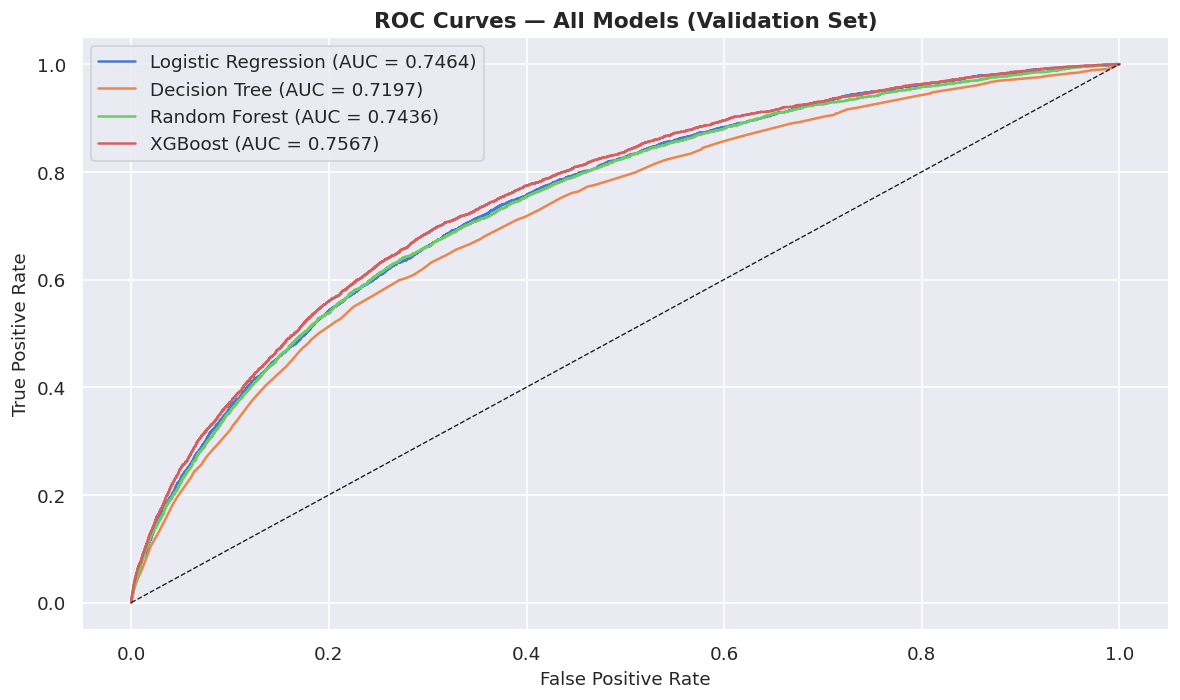

In [96]:
# plot roc curves for all four models on validation set
models = [
    ('Logistic Regression', y_val_prob_lr_weight),
    ('Decision Tree', y_val_prob_dt_weight),
    ('Random Forest', y_val_prob_rf_weight),
    ('XGBoost', y_val_prob_xgb_weight)
]

plt.figure(figsize=(10, 6))

for name, probs in models:
    fpr, tpr, _ = roc_curve(y_val, probs)
    auc = roc_auc_score(y_val, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=0.8)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models (Validation Set)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

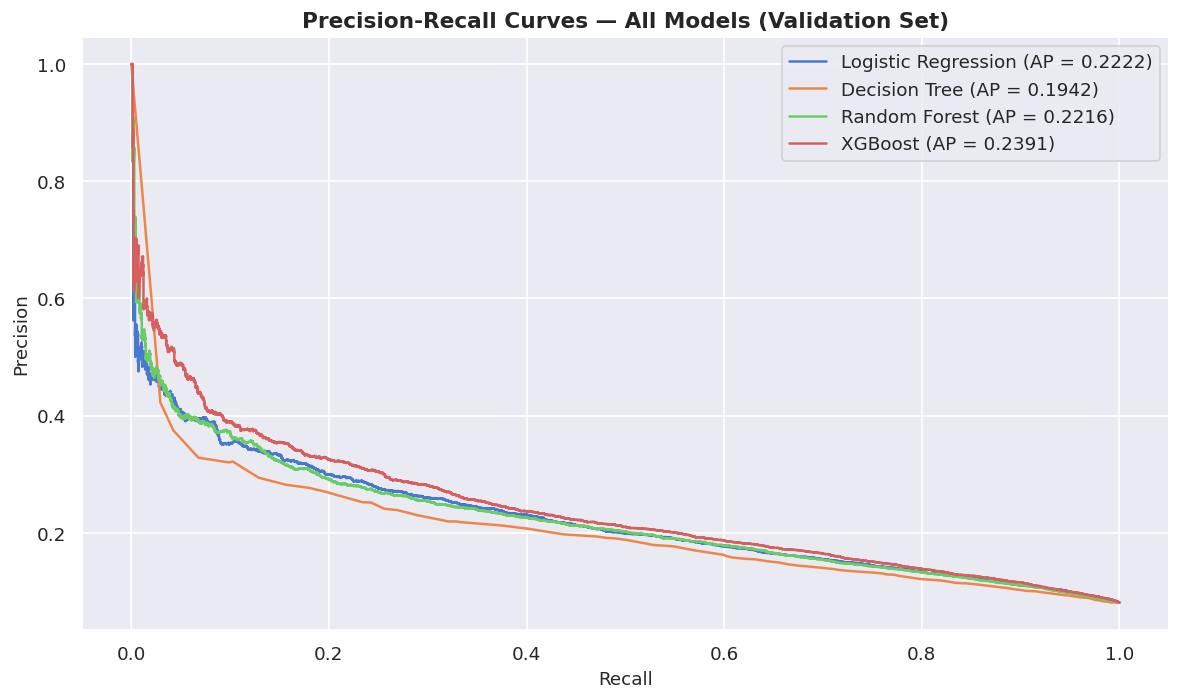

In [97]:
# plot precision-recall curves for all four models on validation set
plt.figure(figsize=(10, 6))

for name, probs in models:
    precision, recall, _ = precision_recall_curve(y_val, probs)
    ap = average_precision_score(y_val, probs)
    plt.plot(recall, precision, label=f'{name} (AP = {ap:.4f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves — All Models (Validation Set)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

In [98]:
#Testing various thresholds
thresholds = np.arange(0.10, 0.61, 0.05)

results = []

for threshold in thresholds:
    y_pred = (y_val_prob_xgb_weight >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1': f1_score(y_val, y_pred)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,Precision,Recall,F1
0,0.10,0.083775,0.995972,0.154549
1,0.15,0.088579,0.983887,0.162525
2,0.20,0.095377,0.963494,0.173572
3,0.25,0.104040,0.933535,0.187216
4,0.30,0.114866,0.902064,0.203782
5,0.35,0.126007,0.854481,0.219627
6,0.40,0.138371,0.799849,0.235928
7,0.45,0.152530,0.740685,0.252966
8,0.50,0.169319,0.677744,0.270948
9,0.55,0.185866,0.601208,0.283948


In [99]:
best_threshold = threshold_results.loc[
    threshold_results['F1'].idxmax(),
    'Threshold'
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.6000000000000002


In [100]:
y_val_pred_tuned = (
    y_val_prob_xgb_weight >= best_threshold
).astype(int)

print(classification_report(y_val, y_val_pred_tuned))

              precision    recall  f1-score   support

           0       0.95      0.82      0.88     45230
           1       0.21      0.52      0.30      3972

    accuracy                           0.80     49202
   macro avg       0.58      0.67      0.59     49202
weighted avg       0.89      0.80      0.84     49202



###EXECUTION STAGE:

In [101]:
# Test probabilities
y_test_prob = best_xgb_weight.predict_proba(X_test)[:, 1]

# ROC-AUC
test_roc_auc = roc_auc_score(y_test, y_test_prob)
print("Test ROC-AUC:", test_roc_auc)

# PR-AUC
test_pr_auc = average_precision_score(y_test, y_test_prob)
print("Test PR-AUC:", test_pr_auc)

# Classification report
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Test ROC-AUC: 0.7622777426348941
Test PR-AUC: 0.25354057873664204

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.71      0.82     56538
           1       0.17      0.68      0.28      4965

    accuracy                           0.71     61503
   macro avg       0.57      0.70      0.55     61503
weighted avg       0.90      0.71      0.78     61503


Confusion Matrix:
[[40320 16218]
 [ 1586  3379]]


In [102]:
#Final threshold tuning
best_threshold = 0.60

y_test_pred_tuned = (
    y_test_prob >= best_threshold
).astype(int)

print("Test Classification Report:")
print(classification_report(y_test, y_test_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned))

Test Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.83      0.89     56538
           1       0.21      0.53      0.30      4965

    accuracy                           0.80     61503
   macro avg       0.58      0.68      0.59     61503
weighted avg       0.89      0.80      0.84     61503

Confusion Matrix:
[[46823  9715]
 [ 2353  2612]]


**OBSERVATION:**

1. Test ROC-AUC of 0.7622 is marginally higher than validation ROC-AUC of 0.7566, indicating no meaningful overfitting and good generalisation to unseen data.
2. Test PR-AUC of 0.2535 is also slightly higher than the validation PR-AUC of 0.239, supporting the model's ability to identify the minority (default) class.
3. At the optimized threshold of 0.60, test Recall is 0.53 and F1-score is 0.30, closely matching the validation performance (Recall 0.52, F1 0.30), confirming that the threshold selection generalises well to the held-out test set.

##RISK TIER SEGMENTATION

In [103]:
# Segment applicants into risk tiers based on predicted probability

def assign_tier(prob):
    if prob < 0.15:
        return 'Low Risk'
    elif prob < 0.60:
        return 'Medium Risk'
    else:
        return 'High Risk'


test_results = pd.DataFrame({
    'actual': y_test.values,
    'predicted_prob': y_test_prob
})

test_results['tier'] = test_results['predicted_prob'].apply(assign_tier)

tier_summary = test_results.groupby('tier').agg(
    applicant_count=('actual', 'count'),
    actual_default_rate=('actual', 'mean'),
    avg_predicted_prob=('predicted_prob', 'mean')
).reset_index()

tier_summary['pct_of_applicants'] = (
    tier_summary['applicant_count'] / len(test_results) * 100
).round(2)

tier_summary['actual_default_rate'] = (
    tier_summary['actual_default_rate'] * 100
).round(2)

tier_summary['avg_predicted_prob'] = (
    tier_summary['avg_predicted_prob'] * 100
).round(2)

tier_order = ['Low Risk', 'Medium Risk', 'High Risk']

tier_summary['tier'] = pd.Categorical(
    tier_summary['tier'],
    categories=tier_order,
    ordered=True
)

tier_summary = tier_summary.sort_values('tier')

print(tier_summary.to_string(index=False))

       tier  applicant_count  actual_default_rate  avg_predicted_prob  pct_of_applicants
   Low Risk             6312                 1.17           10.640000              10.26
Medium Risk            42864                 5.32           35.730000              69.69
  High Risk            12327                21.19           72.199997              20.04


###DEPLOYMENT

In [104]:
import joblib

deployment_objects = {
    'model': best_xgb_weight,

    'num_imputer': num_imputer,
    'cat_imputer': cat_imputer,
    'encoder': encoder,
    'scaler': scaler,

    'numerical_cols': numerical_cols,
    'categorical_cols': categorical_cols,
    'binary_cols': binary_cols,

    'skewed_cols': skewed_cols,
    'lower_caps': lower_caps,
    'upper_caps': upper_caps,

    'property_groups': property_groups,

    'feature_columns': X_train.columns.tolist(),

    'threshold': 0.60
}

joblib.dump(
    deployment_objects,
    'credit1_risk_model.pkl'
)

print("Model and preprocessing objects saved successfully.")
print("Final feature count:", len(X_train.columns))

Model and preprocessing objects saved successfully.
Final feature count: 212


In [105]:
files.download("credit1_risk_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [106]:
print(X_train.shape)
print(X_train.columns.tolist())

(196806, 212)
['cnt_children', 'amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price', 'region_population_relative', 'age_years', 'employment_years', 'registration_years', 'id_publish_years', 'own_car_age', 'flag_emp_phone', 'flag_work_phone', 'flag_phone', 'cnt_fam_members', 'region_rating_client', 'region_rating_client_w_city', 'hour_appr_process_start', 'reg_region_not_live_region', 'reg_region_not_work_region', 'reg_city_not_live_city', 'reg_city_not_work_city', 'live_city_not_work_city', 'ext_source_1', 'ext_source_2', 'ext_source_3', 'totalarea_mode', 'obs_30_cnt_social_circle', 'def_60_cnt_social_circle', 'days_last_phone_change', 'flag_document_2', 'flag_document_3', 'flag_document_6', 'flag_document_7', 'flag_document_8', 'flag_document_9', 'flag_document_11', 'flag_document_13', 'flag_document_14', 'flag_document_15', 'flag_document_16', 'flag_document_17', 'flag_document_18', 'flag_document_19', 'flag_document_21', 'amt_req_credit_bureau_hour', 'amt_req_credit_bu

##Conclusion:
1. Developed an end-to-end credit risk prediction system to identify applicants with a higher likelihood of loan default.
2. Performed comprehensive data preprocessing, including missing-value imputation, outlier treatment, feature engineering, encoding, and scaling.
3. Addressed the significant class imbalance using both SMOTE and class-weighting approaches across multiple models.
4. Evaluated Logistic Regression, Decision Tree, Random Forest, and XGBoost using ROC-AUC, PR-AUC, and classification metrics.
5. XGBoost with scale_pos_weight achieved the best overall performance.
6. Final model achieved 0.7622 Test ROC-AUC and 0.2535 Test PR-AUC.
Optimized the classification threshold to 0.60, achieving 53% recall, 21% precision, and 0.30 F1-score for the default class on the test set.
7. Validation and test results were closely aligned, indicating good generalization with no significant overfitting.
8. Created Low, Medium, and High Risk applicant tiers using predicted default probabilities for practical risk segmentation.
9. Overall, the project demonstrates the application of machine learning for data-driven credit risk assessment and loan default prediction.